In [1]:
import numpy as np
import pandas as pd
import math
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split


In [229]:
df_economic = pd.read_excel(r'Runway_RowData/ECONOMIC FILTERED.xlsx')

df_egypt_agri = pd.read_excel(r'Runway_RowData/AGRICULTURE/EGYPT_AGRICULTURE FILTERED.xlsx')
df_crops_filtered = pd.read_excel(r'Runway_RowData/AGRICULTURE/EGYPT_CROPS FILTERED.xlsx')
df_wheat = pd.read_excel(r'Runway_RowData/AGRICULTURE/WHEAT FILTERED.xlsx')

df_climate = pd.read_excel(r'Runway_RowData/climate/data_stream_moda_spatial_average.xlsx')

df_electricity_sources = pd.read_excel(r'Runway_RowData/Electricity/ember_yearly_electricity-generation - All electricity sources - Egypt - breakdown.csv filtered.xlsx')
df_int_export_1 = pd.read_excel(r'Runway_RowData/Electricity/INT-Export-filtered.xlsx')
df_int_export_2 = pd.read_excel(r'Runway_RowData/Electricity/INT-Export- ء10-08-2026_15-02-20 -filtered.xlsx')

df_aquastat = pd.read_excel(r'Runway_RowData/water/AQUASTAT Dissemination System.csv filtered.xlsx')
df_water_filtered = pd.read_excel(r'Runway_RowData/water/water filtered.xlsx')

## Filtered

### ECONOMIC FILTERED

In [230]:
df_economic.head()

,Country Name,Country Code,Indicator Name,Indicator Code,Year,Value
0,"Egypt, Arab Rep.",EGY,"Agriculture, forestry, and fishing, value adde...",NV.AGR.TOTL.ZS,1960,2.764883e+01
1,"Egypt, Arab Rep.",EGY,Exports of goods and services (% of GDP),NE.EXP.GNFS.ZS,1960,1.986619e+01
2,"Egypt, Arab Rep.",EGY,GDP (current US$),NY.GDP.MKTP.CD,1960,4.206270e+09
3,"Egypt, Arab Rep.",EGY,GDP per capita (current US$),NY.GDP.PCAP.CD,1960,1.563874e+02
4,"Egypt, Arab Rep.",EGY,Imports of goods and services (% of GDP),NE.IMP.GNFS.ZS,1960,2.182551e+01


In [231]:
print("Minimum year:", df_economic["Year"].min())
print("Maximum year:", df_economic["Year"].max())
print("Number of rows:", len(df_economic))

Minimum year: 1960
Maximum year: 2025
Number of rows: 2062


In [232]:
df_economic["Year"].value_counts().sort_index()

Year
1960    11
1961    20
1962    20
1963    20
1964    20
        ..
2021    40
2022    38
2023    29
2024    19
2025    15
Name: count, Length: 66, dtype: int64

In [233]:
df_economic_filtered = df_economic[df_economic["Year"].between(2000, 2023)].copy()

print("Minimum year:", df_economic_filtered["Year"].min())
print("Maximum year:", df_economic_filtered["Year"].max())
print("Number of rows:", len(df_economic_filtered))

Minimum year: 2000
Maximum year: 2023
Number of rows: 947


In [234]:
df_economic_filtered.isnull().sum()

Country Name      0
Country Code      0
Indicator Name    0
Indicator Code    0
Year              0
Value             0
dtype: int64

In [235]:
df_economic_filtered["Year"].value_counts().sort_index()

Year
2000    40
2001    40
2002    40
2003    40
2004    40
2005    40
2006    40
2007    40
2008    40
2009    40
2010    40
2011    40
2012    40
2013    40
2014    40
2015    40
2016    40
2017    40
2018    40
2019    40
2020    40
2021    40
2022    38
2023    29
Name: count, dtype: int64

In [236]:
df_economic_filtered.shape

(947, 6)

In [237]:
df_economic_filtered.head()

,Country Name,Country Code,Indicator Name,Indicator Code,Year,Value
1081,"Egypt, Arab Rep.",EGY,Access to electricity (% of population),EG.ELC.ACCS.ZS,2000,97.700000
1082,"Egypt, Arab Rep.",EGY,Agricultural land (% of land area),AG.LND.AGRI.ZS,2000,3.306042
1083,"Egypt, Arab Rep.",EGY,Agricultural raw materials exports (% of merch...,TX.VAL.AGRI.ZS.UN,2000,5.007055
1084,"Egypt, Arab Rep.",EGY,Agricultural raw materials imports (% of merch...,TM.VAL.AGRI.ZS.UN,2000,4.835680
1085,"Egypt, Arab Rep.",EGY,"Agriculture, forestry, and fishing, value adde...",NV.AGR.TOTL.ZS,2000,15.538077


In [238]:
df_economic_filtered.info()


<class 'pandas.core.frame.DataFrame'>
Index: 947 entries, 1081 to 2027
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Country Name    947 non-null    object 
 1   Country Code    947 non-null    object 
 2   Indicator Name  947 non-null    object 
 3   Indicator Code  947 non-null    object 
 4   Year            947 non-null    int64  
 5   Value           947 non-null    float64
dtypes: float64(1), int64(1), object(4)
memory usage: 51.8+ KB


In [239]:
df_economic_filtered = df_economic_filtered.reset_index(drop=True)

In [240]:
df_economic_filtered.describe(include='all')

,Country Name,Country Code,Indicator Name,Indicator Code,Year,Value
count,947,947,947,947,947.000000,9.470000e+02
unique,1,1,40,40,NaN,NaN
top,"Egypt, Arab Rep.",EGY,Access to electricity (% of population),EG.ELC.ACCS.ZS,NaN,NaN
freq,947,947,24,24,NaN,NaN
mean,NaN,NaN,NaN,NaN,2011.344245,6.814901e+09
std,NaN,NaN,NaN,NaN,6.843291,4.170353e+10
min,NaN,NaN,NaN,NaN,2000.000000,-2.317159e+01
25%,NaN,NaN,NaN,NaN,2005.000000,7.099778e+00
50%,NaN,NaN,NaN,NaN,2011.000000,3.137673e+01
75%,NaN,NaN,NaN,NaN,2017.000000,1.091350e+02


#### Creating Indicator Categories

In [241]:
indicator_categories = {
    # Agriculture
    'AG.LND.AGRI.ZS': 'Agriculture',
    'AG.LND.ARBL.HA': 'Agriculture',
    'AG.CON.FERT.ZS': 'Agriculture',
    'AG.PRD.FOOD.XD': 'Agriculture',
    'SL.AGR.EMPL.ZS': 'Agriculture',
    'NV.AGR.TOTL.ZS': 'Agriculture',
    'NV.AGR.TOTL.KD': 'Agriculture',

    # Water
    'ER.H2O.FWAG.ZS': 'Water',
    'ER.H2O.FWDM.ZS': 'Water',
    'ER.H2O.FWIN.ZS': 'Water',
    'ER.H2O.FWTL.ZS': 'Water',
    'ER.H2O.FWTL.K3': 'Water',
    'ER.H2O.FWST.ZS': 'Water',
    'ER.H2O.INTR.PC': 'Water',
    'ER.H2O.INTR.K3': 'Water',

    # Energy
    'EG.ELC.ACCS.ZS': 'Energy',
    'EG.USE.ELEC.KH.PC': 'Energy',
    'EG.ELC.HYRO.ZS': 'Energy',
    'EG.ELC.NGAS.ZS': 'Energy',
    'EG.ELC.PETR.ZS': 'Energy',
    'EG.ELC.FOSL.ZS': 'Energy',
    'EG.ELC.RNWX.ZS': 'Energy',
    'EG.IMP.CONS.ZS': 'Energy',
    'EG.USE.PCAP.KG.OE': 'Energy',
    'EG.FEC.RNEW.ZS': 'Energy',

    # Trade
    'TX.VAL.AGRI.ZS.UN': 'Trade',
    'TM.VAL.AGRI.ZS.UN': 'Trade',
    'TM.VAL.FOOD.ZS.UN': 'Trade',
    'NE.EXP.GNFS.ZS': 'Trade',
    'NE.IMP.GNFS.ZS': 'Trade',
    'TG.VAL.TOTL.GD.ZS': 'Trade',

    # Economy
    'NY.GDP.MKTP.CD': 'Economy',
    'NY.GDP.MKTP.KD.ZG': 'Economy',
    'NY.GDP.PCAP.CD': 'Economy',
    'NV.IND.TOTL.ZS': 'Economy',
    'NV.SRV.TOTL.ZS': 'Economy',
    'FP.CPI.TOTL.ZG': 'Economy',

    # Population
    'SP.POP.GROW': 'Population',
    'SP.POP.TOTL': 'Population',
    'SP.URB.TOTL.IN.ZS': 'Population'
}

df_economic_filtered['Category'] = (
    df_economic_filtered['Indicator Code'].map(indicator_categories)
)

In [242]:
print(df_economic_filtered['Category'].value_counts(dropna=False))

Category
Energy         236
Water          184
Agriculture    167
Trade          144
Economy        144
Population      72
Name: count, dtype: int64


In [243]:
print(
    df_economic_filtered.loc[
        df_economic_filtered['Category'].isna(),
        'Indicator Code'
    ].unique()
)

[]


In [244]:
## Saced File Economic_Filtered.xlsx
df_economic_filtered.to_csv(
    'Data_Cleaned/Economic_Clean.csv',
    index=False,
)

### AGRICULTURE

In [245]:
df_egypt_agri.columns

Index(['Domain Code', 'Domain', 'Area Code (M49)', 'Area', 'Element Code',
       'Element', 'Item Code (CPC)', 'Item', 'Year Code', 'Year', 'Unit',
       'Value', 'Flag', 'Flag Description', 'Note'],
      dtype='object')

In [246]:
df_crops_filtered.columns

Index(['Domain Code', 'Domain', 'Area Code (M49)', 'Area', 'Element Code',
       'Element', 'Item Code (CPC)', 'Item', 'Year Code', 'Year', 'Unit',
       'Value', 'Flag', 'Flag Description', 'Note'],
      dtype='object')

In [247]:
df_wheat.columns

Index(['Domain Code', 'Domain', 'Area Code (M49)', 'Area', 'Element Code',
       'Element', 'Item Code (CPC)', 'Item', 'Year Code', 'Year', 'Unit',
       'Value', 'Flag', 'Flag Description', 'Note'],
      dtype='object')

In [248]:
df_agriculture = pd.concat(
    [df_egypt_agri,
     df_crops_filtered,
     df_wheat],
    ignore_index=True
)

In [249]:
df_agriculture.head(5)

,Domain Code,Domain,Area Code (M49),Area,Element Code,Element,Item Code (CPC),Item,Year Code,Year,Unit,Value,Flag,Flag Description,Note
0,QCL,Crops and livestock products,818,Egypt,5312,Area harvested,1654.0,"Anise, badian, coriander, cumin, caraway, fenn...",1961,1961,ha,1200.0,E,Estimated value,NaN
1,QCL,Crops and livestock products,818,Egypt,5412,Yield,1654.0,"Anise, badian, coriander, cumin, caraway, fenn...",1961,1961,kg/ha,833.3,E,Estimated value,NaN
2,QCL,Crops and livestock products,818,Egypt,5510,Production,1654.0,"Anise, badian, coriander, cumin, caraway, fenn...",1961,1961,t,1000.0,E,Estimated value,NaN
3,QCL,Crops and livestock products,818,Egypt,5312,Area harvested,1654.0,"Anise, badian, coriander, cumin, caraway, fenn...",1962,1962,ha,1200.0,E,Estimated value,NaN
4,QCL,Crops and livestock products,818,Egypt,5412,Yield,1654.0,"Anise, badian, coriander, cumin, caraway, fenn...",1962,1962,kg/ha,833.3,E,Estimated value,NaN


In [250]:
df_agriculture["Year"].unique()

array([1961, 1962, 1963, 1964, 1965, 1966, 1967, 1968, 1969, 1970, 1971,
       1972, 1973, 1974, 1975, 1976, 1977, 1978, 1979, 1980, 1981, 1982,
       1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993,
       1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004,
       2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015,
       2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024])

In [251]:
df_agriculture_filtered=df_agriculture[df_agriculture["Year"].between(2000, 2023)].copy()

In [252]:
df_agriculture_filtered.head()

,Domain Code,Domain,Area Code (M49),Area,Element Code,Element,Item Code (CPC),Item,Year Code,Year,Unit,Value,Flag,Flag Description,Note
117,QCL,Crops and livestock products,818,Egypt,5312,Area harvested,1654.0,"Anise, badian, coriander, cumin, caraway, fenn...",2000,2000,ha,26000.0,E,Estimated value,NaN
118,QCL,Crops and livestock products,818,Egypt,5412,Yield,1654.0,"Anise, badian, coriander, cumin, caraway, fenn...",2000,2000,kg/ha,846.2,E,Estimated value,NaN
119,QCL,Crops and livestock products,818,Egypt,5510,Production,1654.0,"Anise, badian, coriander, cumin, caraway, fenn...",2000,2000,t,22000.0,E,Estimated value,NaN
120,QCL,Crops and livestock products,818,Egypt,5312,Area harvested,1654.0,"Anise, badian, coriander, cumin, caraway, fenn...",2001,2001,ha,26000.0,E,Estimated value,NaN
121,QCL,Crops and livestock products,818,Egypt,5412,Yield,1654.0,"Anise, badian, coriander, cumin, caraway, fenn...",2001,2001,kg/ha,846.2,E,Estimated value,NaN


In [253]:
df_agriculture_filtered["Unit"].unique()

array(['ha', 'kg/ha', 't'], dtype=object)

ha --> وحدة المساحة 
kg/ha --> انتاجية الفدان
1 فدان =42. هكتار 

In [254]:
df_agriculture_filtered.isnull().sum()

Domain Code            0
Domain                 0
Area Code (M49)        0
Area                   0
Element Code           0
Element                0
Item Code (CPC)        0
Item                   0
Year Code              0
Year                   0
Unit                   0
Value                 20
Flag                   0
Flag Description       0
Note                6181
dtype: int64

In [255]:
df_agriculture_filtered.groupby(
    ['Element', 'Unit']
).size().reset_index(name='Count')

,Element,Unit,Count
0,Area harvested,ha,2070
1,Import quantity,t,24
2,Production,t,2094
3,Yield,kg/ha,2059


In [256]:
# Create a copy
df_Agriculture_clean = df_agriculture_filtered.copy()

# Convert ha to feddan
df_Agriculture_clean.loc[
    df_Agriculture_clean['Unit'] == 'ha', 'Value'
] *= 2.381

# Convert kg/ha to kg/feddan
df_Agriculture_clean.loc[
    df_Agriculture_clean['Unit'] == 'kg/ha', 'Value'
] *= 0.42

# Update Unit names
df_Agriculture_clean['Unit'] = df_Agriculture_clean['Unit'].replace({
    'ha': 'feddan',
    'kg/ha': 'kg/feddan',
    't':'Ton'
})

In [257]:
df_Agriculture_clean.shape

(6247, 15)

In [258]:
df_Agriculture_clean.isnull().sum()

Domain Code            0
Domain                 0
Area Code (M49)        0
Area                   0
Element Code           0
Element                0
Item Code (CPC)        0
Item                   0
Year Code              0
Year                   0
Unit                   0
Value                 20
Flag                   0
Flag Description       0
Note                6181
dtype: int64

In [259]:
df_Agriculture_clean[df_Agriculture_clean['Value'].isnull()]

,Domain Code,Domain,Area Code (M49),Area,Element Code,Element,Item Code (CPC),Item,Year Code,Year,Unit,Value,Flag,Flag Description,Note
768,QCL,Crops and livestock products,818,Egypt,5312,Area harvested,1311.0,Avocados,2020,2020,feddan,NaN,M,Missing value; data cannot exist,NaN
769,QCL,Crops and livestock products,818,Egypt,5510,Production,1311.0,Avocados,2020,2020,Ton,NaN,M,Missing value; data cannot exist,NaN
7619,QCL,Crops and livestock products,818,Egypt,5312,Area harvested,1355.9,Other berries and fruits of the genus vacciniu...,2016,2016,feddan,NaN,M,Missing value; data cannot exist,NaN
7620,QCL,Crops and livestock products,818,Egypt,5510,Production,1355.9,Other berries and fruits of the genus vacciniu...,2016,2016,Ton,NaN,M,Missing value; data cannot exist,NaN
7621,QCL,Crops and livestock products,818,Egypt,5312,Area harvested,1355.9,Other berries and fruits of the genus vacciniu...,2017,2017,feddan,NaN,M,Missing value; data cannot exist,NaN
7622,QCL,Crops and livestock products,818,Egypt,5510,Production,1355.9,Other berries and fruits of the genus vacciniu...,2017,2017,Ton,NaN,M,Missing value; data cannot exist,NaN
7623,QCL,Crops and livestock products,818,Egypt,5312,Area harvested,1355.9,Other berries and fruits of the genus vacciniu...,2018,2018,feddan,NaN,M,Missing value; data cannot exist,NaN
7624,QCL,Crops and livestock products,818,Egypt,5510,Production,1355.9,Other berries and fruits of the genus vacciniu...,2018,2018,Ton,NaN,M,Missing value; data cannot exist,NaN
7625,QCL,Crops and livestock products,818,Egypt,5312,Area harvested,1355.9,Other berries and fruits of the genus vacciniu...,2019,2019,feddan,NaN,M,Missing value; data cannot exist,NaN
7626,QCL,Crops and livestock products,818,Egypt,5510,Production,1355.9,Other berries and fruits of the genus vacciniu...,2019,2019,Ton,NaN,M,Missing value; data cannot exist,NaN


In [260]:
df_Agriculture_clean.dropna(subset=['Value'], inplace=True)

In [261]:
df_Agriculture_clean.duplicated().sum()

np.int64(720)

In [262]:
df_Agriculture_clean.to_csv(
    'Data_cleaned/Agriculture_Clean_General.csv',
    index=False
)

### Electricty

In [263]:
df_electricity_sources.head()

,entity,entity_code,is_aggregate_entity,date,series,is_aggregate_series,generation_twh,generation_share_pct,generation_kwh_per_capita,generation_yoy_change_twh,generation_yoy_change_pct,generation_share_yoy_change_pct_points,generation_yoy_change_kwh_per_capita
0,Egypt,EGY,False,2000,Bioenergy,False,0.00,0.00,0.00,0.00,NaN,0.00,0.00
1,Egypt,EGY,False,2000,Coal,False,0.00,0.00,0.00,0.00,NaN,0.00,0.00
2,Egypt,EGY,False,2000,Gas,False,42.19,57.54,577.26,4.96,13.33,0.91,56.77
3,Egypt,EGY,False,2000,Hydro,False,14.18,19.34,194.00,0.74,5.49,-1.11,6.07
4,Egypt,EGY,False,2000,Other fossil,False,16.87,23.01,230.86,1.82,12.10,0.11,20.41


In [264]:
print("Min Year:", df_electricity_sources['date'].min())
print("Max Year:", df_electricity_sources['date'].max())

Min Year: 2000
Max Year: 2025


In [265]:
df_elec_sources_filtered = df_electricity_sources[df_electricity_sources['date'].between(2000, 2023)].copy()

In [266]:
df_elec_sources_filtered.isnull().sum()

entity                                     0
entity_code                                0
is_aggregate_entity                        0
date                                       0
series                                     0
is_aggregate_series                        0
generation_twh                             0
generation_share_pct                       0
generation_kwh_per_capita                  0
generation_yoy_change_twh                  0
generation_yoy_change_pct                 50
generation_share_yoy_change_pct_points     0
generation_yoy_change_kwh_per_capita       0
dtype: int64

In [267]:
df_elec_sources_filtered.duplicated().sum()

np.int64(0)

In [268]:
df_elec_sources_filtered.shape

(192, 13)

In [269]:
df_elec_sources_filtered.to_csv('Data_cleaned/Electricity_sources_clean.csv', index=False, encoding='utf-8-sig')

In [270]:
df_int_export_1.head()

,Report generated on: 10-08-2026 15:01:29,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,API,Egypt,2000.0000,2001.0000,2002.0000,2003.0000,2004.0000,2005.0000,2006.0000,2007.0000,...,2014.000,2015.000,2016.000,2017.000,2018.000,2019.0000,2020.0000,2021.0000,2022.0000,2023.000
2,INTL.2-7-EGY-MK.A,Capacity (million kW),17.3021,17.1635,17.0626,18.7986,19.4876,21.1696,22.6696,23.3287,...,32.667,36.087,39.548,47.171,57.378,59.0835,59.7355,59.2285,59.3005,62.527
3,INTL.27-7-EGY-MK.A,Nuclear (million kW),0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,...,0.000,0.000,0.000,0.000,0.000,0.0000,0.0000,0.0000,0.0000,0.000
4,INTL.28-7-EGY-MK.A,Fossil fuels (million kW),14.3560,14.3490,14.1810,15.9170,16.5350,18.1690,19.6190,20.1190,...,29.215,32.420,35.857,43.369,52.585,53.3940,53.8020,52.9710,52.9710,55.818


In [271]:
df_int_export_1.drop(
    index=df_int_export_1.index[:1],
    inplace=True
)
df_int_export_1.reset_index(drop=True, inplace=True)

In [272]:
df_int_export_1.head()

,Report generated on: 10-08-2026 15:01:29,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25
0,API,Egypt,2000.0000,2001.0000,2002.0000,2003.0000,2004.0000,2005.0000,2006.0000,2007.0000,...,2014.000,2015.000,2016.000,2017.000,2018.000,2019.0000,2020.0000,2021.0000,2022.0000,2023.000
1,INTL.2-7-EGY-MK.A,Capacity (million kW),17.3021,17.1635,17.0626,18.7986,19.4876,21.1696,22.6696,23.3287,...,32.667,36.087,39.548,47.171,57.378,59.0835,59.7355,59.2285,59.3005,62.527
2,INTL.27-7-EGY-MK.A,Nuclear (million kW),0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,...,0.000,0.000,0.000,0.000,0.000,0.0000,0.0000,0.0000,0.0000,0.000
3,INTL.28-7-EGY-MK.A,Fossil fuels (million kW),14.3560,14.3490,14.1810,15.9170,16.5350,18.1690,19.6190,20.1190,...,29.215,32.420,35.857,43.369,52.585,53.3940,53.8020,52.9710,52.9710,55.818
4,INTL.29-7-EGY-MK.A,Renewables (million kW),2.9461,2.8145,2.8816,2.8816,2.9526,3.0006,3.0506,3.2097,...,3.452,3.667,3.691,3.802,4.793,5.6895,5.9335,6.2575,6.3295,6.709


In [273]:
df_int_export_1.columns = df_int_export_1.iloc[0]
df_int_export_1 = df_int_export_1.iloc[1:].reset_index(drop=True)

In [274]:
df_int_export_1 = df_int_export_1.melt(
    id_vars=['API', 'Egypt'],
    var_name='Year',
    value_name='Value'
)

df_int_export_1.rename(
    columns={'Egypt': 'Indicator'},
    inplace=True
)

df_int_export_1['Year'] = (
    df_int_export_1['Year'].astype(float).astype(int)
)

display(df_int_export_1.head(10))

,API,Indicator,Year,Value
0,INTL.2-7-EGY-MK.A,Capacity (million kW),2000,17.3021
1,INTL.27-7-EGY-MK.A,Nuclear (million kW),2000,0.0000
2,INTL.28-7-EGY-MK.A,Fossil fuels (million kW),2000,14.3560
3,INTL.29-7-EGY-MK.A,Renewables (million kW),2000,2.9461
4,INTL.33-7-EGY-MK.A,Hydroelectricity (million kW),2000,2.8100
5,INTL.34-7-EGY-MK.A,Non-hydroelectric renewables (mill...,2000,0.1361
6,INTL.35-7-EGY-MK.A,Geothermal (million kW),2000,0.0000
7,INTL.36-7-EGY-MK.A,"Solar, tide, wave, fuel cell (...",2000,0.0001
8,INTL.117-7-EGY-MK.A,Tide and wave (million kW),2000,0.0000
9,INTL.116-7-EGY-MK.A,Solar (million kW),2000,0.0001


##### Capacity

In [275]:
indicator_mapping = {
    'Capacity (million kW)': '1',
    'Nuclear (million kW)': '1.1',
    'Fossil fuels (million kW)': '1.2',
    'Renewables (million kW)': '1.3',
    'Hydroelectricity (million kW)': '1.3.1',
    'Non-hydroelectric renewables (million kW)': '1.3.2',
    'Geothermal (million kW)': '1.3.2.1',
    'Solar, tide, wave, fuel cell (million kW)': '1.3.2.2',
    'Tide and wave (million kW)': '1.3.2.2.1',
    'Solar (million kW)': '1.3.2.2.2',
    'Wind (million kW)': '1.3.2.3',
    'Biomass and waste (million kW)': '1.3.2.4',
    'Hydroelectric pumped storage (million kW)': '1.4'
}

df_int_export_1['Level_Indicator'] = (
    df_int_export_1['Indicator'].str.strip().map(indicator_mapping)
)

In [276]:
df_int_export_2.head()

,Report generated on: 10-08-2026 15:02:21,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,API,Egypt,2000.0000,2001.0000,2002.0000,2003.0000,2004.0000,2005.0000,2006.0000,2007.0000,...,2014.0000,2015.0000,2016.0000,2017.0000,2018.000,2019.000,2020.000,2021.000,2022.000,2023.000000
2,INTL.2-12-EGY-BKWH.A,Generation (billion kWh),78.2418,83.3645,89.3012,95.2971,101.4171,108.8086,115.5279,125.2295,...,175.2216,186.3723,189.6281,196.8391,199.501,195.524,202.777,207.591,209.902,213.457805
3,INTL.27-12-EGY-BKWH.A,Nuclear (billion kWh),0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,...,0.0000,0.0000,0.0000,0.0000,0.000,0.000,0.000,0.000,0.000,0.000000
4,INTL.28-12-EGY-BKWH.A,Fossil fuels (billion kWh),64.3090,67.9310,76.1270,81.7960,88.1320,95.4940,101.8660,108.7880,...,159.6090,170.3630,173.7620,181.0060,181.994,173.500,177.295,182.131,183.390,187.679805


In [277]:
df_int_export_2.drop(
    index=df_int_export_2.index[:1],
    inplace=True
)

In [278]:
df_int_export_2.columns = df_int_export_2.iloc[0]
df_int_export_2 = df_int_export_2.iloc[1:].reset_index(drop=True)

In [279]:
df_int_export_2 = df_int_export_2.melt(
    id_vars=['API', 'Egypt'],
    var_name='Year',
    value_name='Value'
)

df_int_export_2.rename(
    columns={'Egypt': 'Indicator'},
    inplace=True
)

df_int_export_2['Year'] = (
    df_int_export_2['Year'].astype(float).astype(int)
)

display(df_int_export_2.head(10))

,API,Indicator,Year,Value
0,INTL.2-12-EGY-BKWH.A,Generation (billion kWh),2000,78.2418
1,INTL.27-12-EGY-BKWH.A,Nuclear (billion kWh),2000,0.0000
2,INTL.28-12-EGY-BKWH.A,Fossil fuels (billion kWh),2000,64.3090
3,INTL.30-12-EGY-BKWH.A,Coal (billion kWh),2000,0.0000
4,INTL.31-12-EGY-BKWH.A,Natural gas (billion kWh),2000,56.7430
5,INTL.32-12-EGY-BKWH.A,Oil (billion kWh),2000,7.5660
6,INTL.2890-12-EGY-BKWH.A,Other gases (billion kWh),2000,0.0000
7,INTL.29-12-EGY-BKWH.A,Renewables (billion kWh),2000,13.9328
8,INTL.33-12-EGY-BKWH.A,Hydroelectricity (billion kWh),2000,13.5600
9,INTL.34-12-EGY-BKWH.A,Non-hydroelectric renewables (bill...,2000,0.3728


In [280]:
df_int_export_2['Value'] = df_int_export_2['Value'] * 1000

In [281]:
indicator_mapping = {
    'Generation (billion kWh)': '1',
    'Nuclear (billion kWh)': '1.1',
    'Fossil fuels (billion kWh)': '1.2',
    'Coal (billion kWh)': '1.2.1',
    'Natural gas (billion kWh)': '1.2.2',
    'Oil (billion kWh)': '1.2.3',
    'Other gases (billion kWh)': '1.2.4',
    'Renewables (billion kWh)': '1.3',
    'Hydroelectricity (billion kWh)': '1.3.1',
    'Non-hydroelectric renewables (billion kWh)': '1.3.2',
    'Geothermal (billion kWh)': '1.3.2.1',
    'Solar, tide, wave, fuel cell (billion kWh)': '1.3.2.2',
    'Tide and wave (billion kWh)': '1.3.2.2.1',
    'Solar (billion kWh)': '1.3.2.2.2',
    'Wind (billion kWh)': '1.3.2.3',
    'Biomass and waste (billion kWh)': '1.3.2.4',
    'Hydroelectric pumped storage (billion kWh)': '1.4'
}

df_int_export_2['Level_Indicator'] = (
    df_int_export_2['Indicator'].str.strip().map(indicator_mapping)
)

In [282]:
df_int_export = pd.concat(
    [df_int_export_1, df_int_export_2],
    ignore_index=True
)

In [283]:
df_int_export['Indicator'] = df_int_export['Indicator'].str.replace(
    'billion', 'million', regex=False
)

In [284]:

df_int_export['Indicator'] = df_int_export['Indicator'].astype(str).str.strip()

In [285]:
df_int_export['Indicator'].unique()

array(['Capacity (million kW)', 'Nuclear (million kW)',
       'Fossil fuels (million kW)', 'Renewables (million kW)',
       'Hydroelectricity (million kW)',
       'Non-hydroelectric renewables (million kW)',
       'Geothermal (million kW)',
       'Solar, tide, wave, fuel cell (million kW)',
       'Tide and wave (million kW)', 'Solar (million kW)',
       'Wind (million kW)', 'Biomass and waste (million kW)',
       'Hydroelectric pumped storage (million kW)',
       'Generation (million kWh)', 'Nuclear (million kWh)',
       'Fossil fuels (million kWh)', 'Coal (million kWh)',
       'Natural gas (million kWh)', 'Oil (million kWh)',
       'Other gases (million kWh)', 'Renewables (million kWh)',
       'Hydroelectricity (million kWh)',
       'Non-hydroelectric renewables (million kWh)',
       'Geothermal (million kWh)',
       'Solar, tide, wave, fuel cell (million kWh)',
       'Tide and wave (million kWh)', 'Solar (million kWh)',
       'Wind (million kWh)', 'Biomass and waste

In [286]:
df_int_export.head()

,API,Indicator,Year,Value,Level_Indicator
0,INTL.2-7-EGY-MK.A,Capacity (million kW),2000,17.3021,1
1,INTL.27-7-EGY-MK.A,Nuclear (million kW),2000,0.0000,1.1
2,INTL.28-7-EGY-MK.A,Fossil fuels (million kW),2000,14.3560,1.2
3,INTL.29-7-EGY-MK.A,Renewables (million kW),2000,2.9461,1.3
4,INTL.33-7-EGY-MK.A,Hydroelectricity (million kW),2000,2.8100,1.3.1


In [287]:
df_int_export.isnull().sum()

API                0
Indicator          0
Year               0
Value              1
Level_Indicator    0
dtype: int64

In [288]:
df_int_export.dropna(subset=['Value'], inplace=True)

In [289]:
df_int_export.to_csv('Data_cleaned/Electricty_export.csv', index=False, encoding='utf-8-sig')

### Water

In [290]:
df_aquastat.columns

Index(['m49', 'VariableGroup', 'Subgroup', 'Variable', 'Area', 'Year', 'Value',
       'Unit', 'Symbol', 'IsAggregate'],
      dtype='object')

In [291]:
df_water_filtered.columns

Index(['m49', 'VariableGroup', 'Subgroup', 'Variable', 'Area', 'Year', 'Value',
       'Unit', 'Symbol', 'IsAggregate'],
      dtype='object')

In [292]:
df_Water = pd.concat(
    [df_aquastat, df_water_filtered],
    ignore_index=True
)

In [293]:
df_Water.head()

,m49,VariableGroup,Subgroup,Variable,Area,Year,Value,Unit,Symbol,IsAggregate
0,818,Irrigation and drainage development,Area equipped for irrigation by source of water,Area equipped for irrigation by direct use of ...,Egypt,1990,19.714286,1000 ha,I,False
1,818,Irrigation and drainage development,Area equipped for irrigation by source of water,Area equipped for irrigation by direct use of ...,Egypt,1991,14.142857,1000 ha,I,False
2,818,Irrigation and drainage development,Area equipped for irrigation by source of water,Area equipped for irrigation by direct use of ...,Egypt,1992,8.571429,1000 ha,I,False
3,818,Irrigation and drainage development,Area equipped for irrigation by source of water,Area equipped for irrigation by direct use of ...,Egypt,1993,3.000000,1000 ha,A,False
4,818,Irrigation and drainage development,Area equipped for irrigation by source of water,Area equipped for irrigation by direct use of ...,Egypt,1994,7.875000,1000 ha,I,False


In [294]:
df_Water["Year"].unique()

array([1990, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1999, 2000, 2001,
       2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012,
       2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023])

In [295]:
df_Water_filtered=df_Water[df_Water["Year"].between(2000, 2023)].copy()

In [296]:
df_Water_filtered['Unit'].unique()

array(['1000 ha', '%', '10^9 m3/year', 'mm/year', 'm3/inhab/year',
       'current US$', nan, 'current US$/inhab', 'inhab/km2', '1000 inhab',
       'US$/m3'], dtype=object)

In [297]:
# 1. تحويل 1000 ha إلى فدان
mask = df_Water_filtered['Unit'] == '1000 ha'

df_Water_filtered.loc[mask, 'Value'] *= 2.38095*1000
df_Water_filtered.loc[mask, 'Unit'] = 'feddan'


# 2. تحويل 1000 inhab إلى inhab --. نسمة 
mask = df_Water_filtered['Unit'] == '1000 inhab'

df_Water_filtered.loc[mask, 'Value'] *= 1000
df_Water_filtered.loc[mask, 'Unit'] = 'inhabitants'

In [298]:
unit_mapping = {
    'm3/inhab/year': 'm3/person/year',
    'inhab/km2': 'inhabitants/km2',
    'current US$/inhab': 'USD/person',
    'current US$': 'USD'
}

df_Water_filtered['Unit'] = (
    df_Water_filtered['Unit'].replace(unit_mapping)
)

In [299]:
df_Water_filtered['Unit'].unique()

array(['feddan', '%', '10^9 m3/year', 'mm/year', 'm3/person/year', 'USD',
       nan, 'USD/person', 'inhabitants/km2', 'inhabitants', 'US$/m3'],
      dtype=object)

In [300]:
df_Water_filtered.isnull().sum()

m49              0
VariableGroup    0
Subgroup         0
Variable         0
Area             0
Year             0
Value            0
Unit             3
Symbol           0
IsAggregate      0
dtype: int64

In [301]:
df_Water_filtered.dropna(subset=['Unit'], inplace=True)

In [302]:
df_Water_filtered.duplicated().sum()

np.int64(147)

In [303]:
df_Water_filtered.to_csv('Data_cleaned/Water_Clean.csv', index=False, encoding='utf-8-sig')

### Climate

In [304]:
df_climate.head()

,date,t2m,swvl1,slhf,ssrd,pev,ro,sro,e,u10,v10,tp
0,2000-01-01,284.39896,0.022670,-418747.44,15392980,-0.003199,1.160945e-06,1.058694e-06,-0.000167,0.956239,-1.717535,0.000193
1,2000-02-01,285.49475,0.018762,-330796.03,19048732,-0.003940,3.160599e-07,2.929411e-07,-0.000132,0.753881,-2.435263,0.000071
2,2000-03-01,288.81296,0.012703,-279489.20,23965248,-0.005723,2.016055e-07,1.754155e-07,-0.000112,-0.161050,-2.646390,0.000035
3,2000-04-01,296.32556,0.007498,-257909.42,27153320,-0.007861,5.963418e-08,3.243464e-08,-0.000103,0.301114,-1.460344,0.000009
4,2000-05-01,299.06104,0.005635,-324336.30,28813656,-0.008973,6.378748e-08,3.784632e-08,-0.000130,-0.127819,-2.806284,0.000010


In [305]:
df_climate.columns

Index(['date', 't2m', 'swvl1', 'slhf', 'ssrd', 'pev', 'ro', 'sro', 'e', 'u10',
       'v10', 'tp'],
      dtype='object')

In [306]:
df_climate['date'] = pd.to_datetime(df_climate['date'])

df_climate['Year'] = df_climate['date'].dt.year

agg_rules = {
    't2m': 'mean',
    'swvl1': 'mean',
    'slhf': 'sum',
    'ssrd': 'sum',
    'pev': 'sum',
    'ro': 'sum',
    'sro': 'sum',
    'e': 'sum',
    'u10': 'mean',
    'v10': 'mean',
    'tp': 'sum'
}

df_climate_annual = (
    df_climate.groupby('Year')
      .agg(agg_rules)
      .reset_index()
)

In [307]:
df_climate_annual.head()

,Year,t2m,swvl1,slhf,ssrd,pev,ro,sro,e,u10,v10,tp
0,2000,294.409063,0.009936,-3892321.44,275248859,-0.078021,0.000003,0.000003,-0.001556,0.400113,-2.594168,0.000552
1,2001,295.091858,0.007815,-3638552.25,275589158,-0.079554,0.000002,0.000002,-0.001455,0.328838,-2.338997,0.000381
2,2002,295.183013,0.009754,-4053215.18,274151582,-0.080010,0.000004,0.000003,-0.001621,0.211584,-2.276578,0.000568
3,2003,295.070053,0.008595,-3814634.56,274354061,-0.080470,0.000004,0.000002,-0.001525,0.371083,-2.143402,0.000450
4,2004,295.122602,0.009150,-3787883.60,274677803,-0.080526,0.000003,0.000002,-0.001515,0.190732,-2.265247,0.000455


In [308]:
df_climate_annual.isnull().sum()

Year     0
t2m      0
swvl1    0
slhf     0
ssrd     0
pev      0
ro       0
sro      0
e        0
u10      0
v10      0
tp       0
dtype: int64

In [309]:
df_climate_annual.shape

(24, 12)

In [310]:
df_climate_annual.to_csv('Data_cleaned/Climate_Cleaned.csv', index=False, encoding='utf-8-sig')

### EDA 

In [311]:

datasets = {
    "Climate": df_climate_annual,
    "Water": df_Water_filtered,
    "International Energy Trade": df_int_export,
    "Electricity Sources": df_elec_sources_filtered,
    "Agriculture": df_Agriculture_clean,
    "Economy": df_economic_filtered
}


In [312]:
for name, df in datasets.items():
    print("=" * 60)
    print(f"Dataset: {name}")
    print("=" * 60)

    print("Rows:", df.shape[0])
    print("Columns:", df.shape[1])

    if "Year" in df.columns:
        print("Year Range:", df["Year"].min(), "-", df["Year"].max())

    print("Column Names:", df.columns.tolist())
    print("\n")


Dataset: Climate
Rows: 24
Columns: 12
Year Range: 2000 - 2023
Column Names: ['Year', 't2m', 'swvl1', 'slhf', 'ssrd', 'pev', 'ro', 'sro', 'e', 'u10', 'v10', 'tp']


Dataset: Water
Rows: 1528
Columns: 10
Year Range: 2000 - 2023
Column Names: ['m49', 'VariableGroup', 'Subgroup', 'Variable', 'Area', 'Year', 'Value', 'Unit', 'Symbol', 'IsAggregate']


Dataset: International Energy Trade
Rows: 719
Columns: 5
Year Range: 2000 - 2023
Column Names: ['API', 'Indicator', 'Year', 'Value', 'Level_Indicator']


Dataset: Electricity Sources
Rows: 192
Columns: 13
Column Names: ['entity', 'entity_code', 'is_aggregate_entity', 'date', 'series', 'is_aggregate_series', 'generation_twh', 'generation_share_pct', 'generation_kwh_per_capita', 'generation_yoy_change_twh', 'generation_yoy_change_pct', 'generation_share_yoy_change_pct_points', 'generation_yoy_change_kwh_per_capita']


Dataset: Agriculture
Rows: 6227
Columns: 15
Year Range: 2000 - 2023
Column Names: ['Domain Code', 'Domain', 'Area Code (M49)', 'A

In [313]:

for name, df in datasets.items():

    print("=" * 70)
    print(f"Dataset: {name}")
    print("=" * 70)
    
    print("\nDataset Information:")
    display(df.info())
   

    print("\n")


Dataset: Climate

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 12 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Year    24 non-null     int32  
 1   t2m     24 non-null     float64
 2   swvl1   24 non-null     float64
 3   slhf    24 non-null     float64
 4   ssrd    24 non-null     int64  
 5   pev     24 non-null     float64
 6   ro      24 non-null     float64
 7   sro     24 non-null     float64
 8   e       24 non-null     float64
 9   u10     24 non-null     float64
 10  v10     24 non-null     float64
 11  tp      24 non-null     float64
dtypes: float64(10), int32(1), int64(1)
memory usage: 2.3 KB


None



Dataset: Water

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
Index: 1528 entries, 9 to 1782
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   m49            1528 non-null   int64  
 1   VariableGroup  1528 non-null   object 
 2   Subgroup       1528 non-null   object 
 3   Variable       1528 non-null   object 
 4   Area           1528 non-null   object 
 5   Year           1528 non-null   int64  
 6   Value          1528 non-null   float64
 7   Unit           1528 non-null   object 
 8   Symbol         1528 non-null   object 
 9   IsAggregate    1528 non-null   bool   
dtypes: bool(1), float64(1), int64(2), object(6)
memory usage: 120.9+ KB


None



Dataset: International Energy Trade

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
Index: 719 entries, 0 to 718
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   API              719 non-null    object 
 1   Indicator        719 non-null    object 
 2   Year             719 non-null    int64  
 3   Value            719 non-null    float64
 4   Level_Indicator  719 non-null    object 
dtypes: float64(1), int64(1), object(3)
memory usage: 33.7+ KB


None

... (2 outputs left out)



Dataset: Agriculture

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
Index: 6227 entries, 117 to 16229
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Domain Code       6227 non-null   object 
 1   Domain            6227 non-null   object 
 2   Area Code (M49)   6227 non-null   int64  
 3   Area              6227 non-null   object 
 4   Element Code      6227 non-null   int64  
 5   Element           6227 non-null   object 
 6   Item Code (CPC)   6227 non-null   float64
 7   Item              6227 non-null   object 
 8   Year Code         6227 non-null   int64  
 9   Year              6227 non-null   int64  
 10  Unit              6227 non-null   object 
 11  Value             6227 non-null   float64
 12  Flag              6227 non-null   object 
 13  Flag Description  6227 non-null   object 
 14  Note              66 non-null     object 
dtypes: float64(2), int64(4), object(9)
memory usag

None



Dataset: Economy

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 947 entries, 0 to 946
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Country Name    947 non-null    object 
 1   Country Code    947 non-null    object 
 2   Indicator Name  947 non-null    object 
 3   Indicator Code  947 non-null    object 
 4   Year            947 non-null    int64  
 5   Value           947 non-null    float64
 6   Category        947 non-null    object 
dtypes: float64(1), int64(1), object(5)
memory usage: 51.9+ KB


None

In [314]:

for name, df in datasets.items():

    print("=" * 70)
    print(f"Dataset: {name}")
    print("=" * 70)

    print("\nNumerical Statistics:")
    display(df.describe(include='all'))

    print("\n")


Dataset: Climate

Numerical Statistics:


,Year,t2m,swvl1,slhf,ssrd,pev,ro,sro,e,u10,v10,tp
count,24.000000,24.000000,24.000000,2.400000e+01,2.400000e+01,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000
mean,2011.500000,295.443023,0.009581,-3.948513e+06,2.682273e+08,-0.078506,0.000004,0.000003,-0.001579,0.281189,-2.264957,0.000561
std,7.071068,0.527932,0.001276,4.830980e+05,2.299299e+07,0.008076,0.000002,0.000002,0.000193,0.117354,0.162148,0.000179
min,2000.000000,294.409063,0.007386,-4.987617e+06,1.641358e+08,-0.083473,0.000002,0.000002,-0.001994,0.056662,-2.594168,0.000352
25%,2005.750000,295.116012,0.008732,-4.075016e+06,2.730900e+08,-0.080764,0.000003,0.000002,-0.001629,0.205388,-2.361815,0.000454
50%,2011.500000,295.314370,0.009392,-3.906905e+06,2.741291e+08,-0.080438,0.000003,0.000003,-0.001562,0.294914,-2.277883,0.000527
75%,2017.250000,295.689337,0.010410,-3.807947e+06,2.745729e+08,-0.079601,0.000004,0.000003,-0.001523,0.387658,-2.141941,0.000570
max,2023.000000,296.750361,0.013032,-2.319198e+06,2.755892e+08,-0.042305,0.000008,0.000007,-0.000927,0.447225,-1.944379,0.001146




Dataset: Water

Numerical Statistics:


,m49,VariableGroup,Subgroup,Variable,Area,Year,Value,Unit,Symbol,IsAggregate
count,1528.0,1528,1528,1528,1528,1528.00000,1.528000e+03,1528,1528,1528
unique,NaN,4,14,128,1,NaN,NaN,10,4,1
top,NaN,Irrigation and drainage development,Irrigated crop area and cropping intensity,Area equipped for irrigation by direct use of ...,Egypt,NaN,NaN,feddan,I,False
freq,NaN,1011,861,27,1528,NaN,NaN,930,1141,1528
mean,818.0,NaN,NaN,NaN,NaN,2014.36911,8.591324e+07,NaN,NaN,NaN
std,0.0,NaN,NaN,NaN,NaN,7.34962,1.915743e+09,NaN,NaN,NaN
min,818.0,NaN,NaN,NaN,NaN,2000.00000,0.000000e+00,NaN,NaN,NaN
25%,818.0,NaN,NaN,NaN,NaN,2008.00000,8.279032e+01,NaN,NaN,NaN
50%,818.0,NaN,NaN,NaN,NaN,2016.00000,9.047610e+04,NaN,NaN,NaN
75%,818.0,NaN,NaN,NaN,NaN,2021.00000,8.357134e+05,NaN,NaN,NaN




Dataset: International Energy Trade

Numerical Statistics:


,API,Indicator,Year,Value,Level_Indicator
count,719,719,719.000000,719.000000,719
unique,30,30,NaN,NaN,17
top,INTL.2-7-EGY-MK.A,Capacity (million kW),NaN,NaN,1
freq,24,24,NaN,NaN,48
mean,NaN,NaN,2011.484006,15565.678813,NaN
std,NaN,NaN,6.918504,43064.020364,NaN
min,NaN,NaN,2000.000000,0.000000,NaN
25%,NaN,NaN,2005.500000,0.000000,NaN
50%,NaN,NaN,2011.000000,1.380000,NaN
75%,NaN,NaN,2017.000000,1511.500000,NaN


... (2 outputs left out)



Dataset: Agriculture

Numerical Statistics:


,Domain Code,Domain,Area Code (M49),Area,Element Code,Element,Item Code (CPC),Item,Year Code,Year,Unit,Value,Flag,Flag Description,Note
count,6227,6227,6227.0,6227,6227.000000,6227,6227.000000,6227,6227.000000,6227.000000,6227,6.227000e+03,6227,6227,66
unique,2,1,NaN,1,NaN,4,NaN,79,NaN,NaN,3,NaN,4,4,2
top,QCL,Crops and livestock products,NaN,Egypt,NaN,Production,NaN,Wheat,NaN,NaN,Ton,NaN,A,Official value,Unofficial figure
freq,6203,6227,NaN,6227,NaN,2084,NaN,168,NaN,NaN,2108,NaN,4699,4699,56
mean,NaN,NaN,818.0,NaN,5412.479203,NaN,1260.863045,NaN,2011.489321,2011.489321,NaN,6.665789e+05,NaN,NaN,NaN
std,NaN,NaN,0.0,NaN,81.696399,NaN,485.892505,NaN,6.926720,6.926720,NaN,2.118665e+06,NaN,NaN,NaN
min,NaN,NaN,818.0,NaN,5312.000000,NaN,111.000000,NaN,2000.000000,2000.000000,NaN,0.000000e+00,NaN,NaN,NaN
25%,NaN,NaN,818.0,NaN,5312.000000,NaN,1234.000000,NaN,2005.000000,2005.000000,NaN,4.088658e+03,NaN,NaN,NaN
50%,NaN,NaN,818.0,NaN,5412.000000,NaN,1323.000000,NaN,2011.000000,2011.000000,NaN,1.909274e+04,NaN,NaN,NaN
75%,NaN,NaN,818.0,NaN,5510.000000,NaN,1530.000000,NaN,2017.000000,2017.000000,NaN,2.041291e+05,NaN,NaN,NaN




Dataset: Economy

Numerical Statistics:


,Country Name,Country Code,Indicator Name,Indicator Code,Year,Value,Category
count,947,947,947,947,947.000000,9.470000e+02,947
unique,1,1,40,40,NaN,NaN,6
top,"Egypt, Arab Rep.",EGY,Access to electricity (% of population),EG.ELC.ACCS.ZS,NaN,NaN,Energy
freq,947,947,24,24,NaN,NaN,236
mean,NaN,NaN,NaN,NaN,2011.344245,6.814901e+09,NaN
std,NaN,NaN,NaN,NaN,6.843291,4.170353e+10,NaN
min,NaN,NaN,NaN,NaN,2000.000000,-2.317159e+01,NaN
25%,NaN,NaN,NaN,NaN,2005.000000,7.099778e+00,NaN
50%,NaN,NaN,NaN,NaN,2011.000000,3.137673e+01,NaN
75%,NaN,NaN,NaN,NaN,2017.000000,1.091350e+02,NaN


In [315]:

for name, df in datasets.items():

    print("=" * 70)
    print(f"Dataset: {name}")
    print("=" * 70)

    missing_summary = pd.DataFrame({
        "Missing Count": df.isnull().sum(),
        "Missing Percentage": (df.isnull().mean() * 100).round(2),
        "Non-Missing Count": df.notnull().sum()
    })

    missing_summary = missing_summary[
        missing_summary["Missing Count"] > 0
    ].sort_values("Missing Percentage", ascending=False)

    if missing_summary.empty:
        print("No Missing Values Found!")
    else:
        display(missing_summary)

    print("\n")


Dataset: Climate
No Missing Values Found!


Dataset: Water
No Missing Values Found!


Dataset: International Energy Trade
No Missing Values Found!


Dataset: Electricity Sources


,Missing Count,Missing Percentage,Non-Missing Count
generation_yoy_change_pct,50,26.04,142




Dataset: Agriculture


,Missing Count,Missing Percentage,Non-Missing Count
Note,6161,98.94,66




Dataset: Economy
No Missing Values Found!




In [316]:

for name, df in datasets.items():

    print("=" * 70)
    print(f"Dataset: {name}")
    print("=" * 70)

    duplicates_count = df.duplicated().sum()
    duplicates_percentage = (duplicates_count / len(df)) * 100

    print("Total Rows:", len(df))
    print("Duplicate Rows:", duplicates_count)
    print("Duplicate Percentage:", round(duplicates_percentage, 2), "%")


    print("\n")


Dataset: Climate
Total Rows: 24
Duplicate Rows: 0
Duplicate Percentage: 0.0 %


Dataset: Water
Total Rows: 1528
Duplicate Rows: 147
Duplicate Percentage: 9.62 %


Dataset: International Energy Trade
Total Rows: 719
Duplicate Rows: 0
Duplicate Percentage: 0.0 %


Dataset: Electricity Sources
Total Rows: 192
Duplicate Rows: 0
Duplicate Percentage: 0.0 %


Dataset: Agriculture
Total Rows: 6227
Duplicate Rows: 720
Duplicate Percentage: 11.56 %


Dataset: Economy
Total Rows: 947
Duplicate Rows: 0
Duplicate Percentage: 0.0 %




### Split All Data

df_climate_annual و df_Water_filtered و df_int_export و df_elec_sources_filtered و  df_Agriculture_clean و df_economic_filtered

In [317]:
df_elec_sources_filtered.head()

,entity,entity_code,is_aggregate_entity,date,series,is_aggregate_series,generation_twh,generation_share_pct,generation_kwh_per_capita,generation_yoy_change_twh,generation_yoy_change_pct,generation_share_yoy_change_pct_points,generation_yoy_change_kwh_per_capita
0,Egypt,EGY,False,2000,Bioenergy,False,0.00,0.00,0.00,0.00,NaN,0.00,0.00
1,Egypt,EGY,False,2000,Coal,False,0.00,0.00,0.00,0.00,NaN,0.00,0.00
2,Egypt,EGY,False,2000,Gas,False,42.19,57.54,577.26,4.96,13.33,0.91,56.77
3,Egypt,EGY,False,2000,Hydro,False,14.18,19.34,194.00,0.74,5.49,-1.11,6.07
4,Egypt,EGY,False,2000,Other fossil,False,16.87,23.01,230.86,1.82,12.10,0.11,20.41


In [318]:
df_elec_sources_filtered.rename(
    columns={'date': 'Year'},
    inplace=True
)

In [319]:
datasets = {
    "Climate": df_climate_annual,
    "Water": df_Water_filtered,
    "International Energy Trade": df_int_export,
    "Electricity Sources": df_elec_sources_filtered,
    "Agriculture": df_Agriculture_clean,
    "Economy":df_economic_filtered
}

for name, df in datasets.items():
    print(f"\n{name}")
    print("Min Year:", df["Year"].min())
    print("Max Year:", df["Year"].max())
    print("Unique Years:", sorted(df["Year"].unique()))
    print("Rows:", len(df))


Climate
Min Year: 2000
Max Year: 2023
Unique Years: [np.int32(2000), np.int32(2001), np.int32(2002), np.int32(2003), np.int32(2004), np.int32(2005), np.int32(2006), np.int32(2007), np.int32(2008), np.int32(2009), np.int32(2010), np.int32(2011), np.int32(2012), np.int32(2013), np.int32(2014), np.int32(2015), np.int32(2016), np.int32(2017), np.int32(2018), np.int32(2019), np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023)]
Rows: 24

Water
Min Year: 2000
Max Year: 2023
Unique Years: [np.int64(2000), np.int64(2001), np.int64(2002), np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023)]
Rows: 1528

International Energy Trade
Min Year: 2000
Max Year: 2023
Unique Years: [np.int64(2000), np.int64(2001), n

In [320]:
# Datasets
datasets = {
    "climate_annual": df_climate_annual,
    "Water_filtered": df_Water_filtered,
    "int_export": df_int_export,
    "elec_sources_filtered": df_elec_sources_filtered,
    "Agriculture_clean": df_Agriculture_clean,
    "economic_filtered": df_economic_filtered
}

# Time-Based Train-Test Split
for name, df in datasets.items():

    # Sort by Year
    df = df.sort_values('Year').reset_index(drop=True)

    # Split 80% Train / 20% Test
    split = int(len(df) * 0.8)

    # Train
    globals()[f"df_{name}_train"] = df.iloc[:split].copy()

    # Test
    globals()[f"df_{name}_test"] = df.iloc[split:].copy()

### Cleaning

In [321]:
for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame) and (
        name.endswith('_train') or name.endswith('_test')
    ):
        print(f"{name}: {obj.shape}")

df_climate_annual_train: (19, 12)
df_climate_annual_test: (5, 12)
df_Water_filtered_train: (1222, 10)
df_Water_filtered_test: (306, 10)
df_int_export_train: (575, 5)
df_int_export_test: (144, 5)
df_elec_sources_filtered_train: (153, 13)
df_elec_sources_filtered_test: (39, 13)
df_Agriculture_clean_train: (4981, 15)
df_Agriculture_clean_test: (1246, 15)
df_economic_filtered_train: (757, 7)
df_economic_filtered_test: (190, 7)


In [322]:
dfs = [
    df_climate_annual_train, df_climate_annual_test,
    df_Water_filtered_train, df_Water_filtered_test,
    df_int_export_train, df_int_export_test,
    df_elec_sources_filtered_train, df_elec_sources_filtered_test,
    df_Agriculture_clean_train, df_Agriculture_clean_test,
    df_economic_filtered_train, df_economic_filtered_test
]

df_names = [
    "Climate Train", "Climate Test",
    "Water Train", "Water Test",
    "International Export Train", "International Export Test",
    "Electricity Train", "Electricity Test",
    "Agriculture Train", "Agriculture Test",
    "Economic Train", "Economic Test"
]

for name, df in zip(df_names, dfs):
    print(f"\nNulls in {name}:")
    display(df.isnull().sum())
    print("-" * 40)


Nulls in Climate Train:


Year     0
t2m      0
swvl1    0
slhf     0
ssrd     0
pev      0
ro       0
sro      0
e        0
u10      0
v10      0
tp       0
dtype: int64

----------------------------------------

Nulls in Climate Test:


Year     0
t2m      0
swvl1    0
slhf     0
ssrd     0
pev      0
ro       0
sro      0
e        0
u10      0
v10      0
tp       0
dtype: int64

----------------------------------------

Nulls in Water Train:


m49              0
VariableGroup    0
Subgroup         0
Variable         0
Area             0
Year             0
Value            0
Unit             0
Symbol           0
IsAggregate      0
dtype: int64

... (15 outputs left out)

Country Name      0
Country Code      0
Indicator Name    0
Indicator Code    0
Year              0
Value             0
Category          0
dtype: int64

----------------------------------------

Nulls in Economic Test:


Country Name      0
Country Code      0
Indicator Name    0
Indicator Code    0
Year              0
Value             0
Category          0
dtype: int64

----------------------------------------


In [323]:
display(df_elec_sources_filtered_train.isnull().sum())
print("=="*50)
display(df_elec_sources_filtered_test.isnull().sum())

entity                                     0
entity_code                                0
is_aggregate_entity                        0
Year                                       0
series                                     0
is_aggregate_series                        0
generation_twh                             0
generation_share_pct                       0
generation_kwh_per_capita                  0
generation_yoy_change_twh                  0
generation_yoy_change_pct                 41
generation_share_yoy_change_pct_points     0
generation_yoy_change_kwh_per_capita       0
dtype: int64

entity                                    0
entity_code                               0
is_aggregate_entity                       0
Year                                      0
series                                    0
is_aggregate_series                       0
generation_twh                            0
generation_share_pct                      0
generation_kwh_per_capita                 0
generation_yoy_change_twh                 0
generation_yoy_change_pct                 9
generation_share_yoy_change_pct_points    0
generation_yoy_change_kwh_per_capita      0
dtype: int64

In [324]:
df_elec_sources_filtered_train.drop(
    columns=['generation_yoy_change_pct'],
    inplace=True
)

df_elec_sources_filtered_test.drop(
    columns=['generation_yoy_change_pct'],
    inplace=True
)

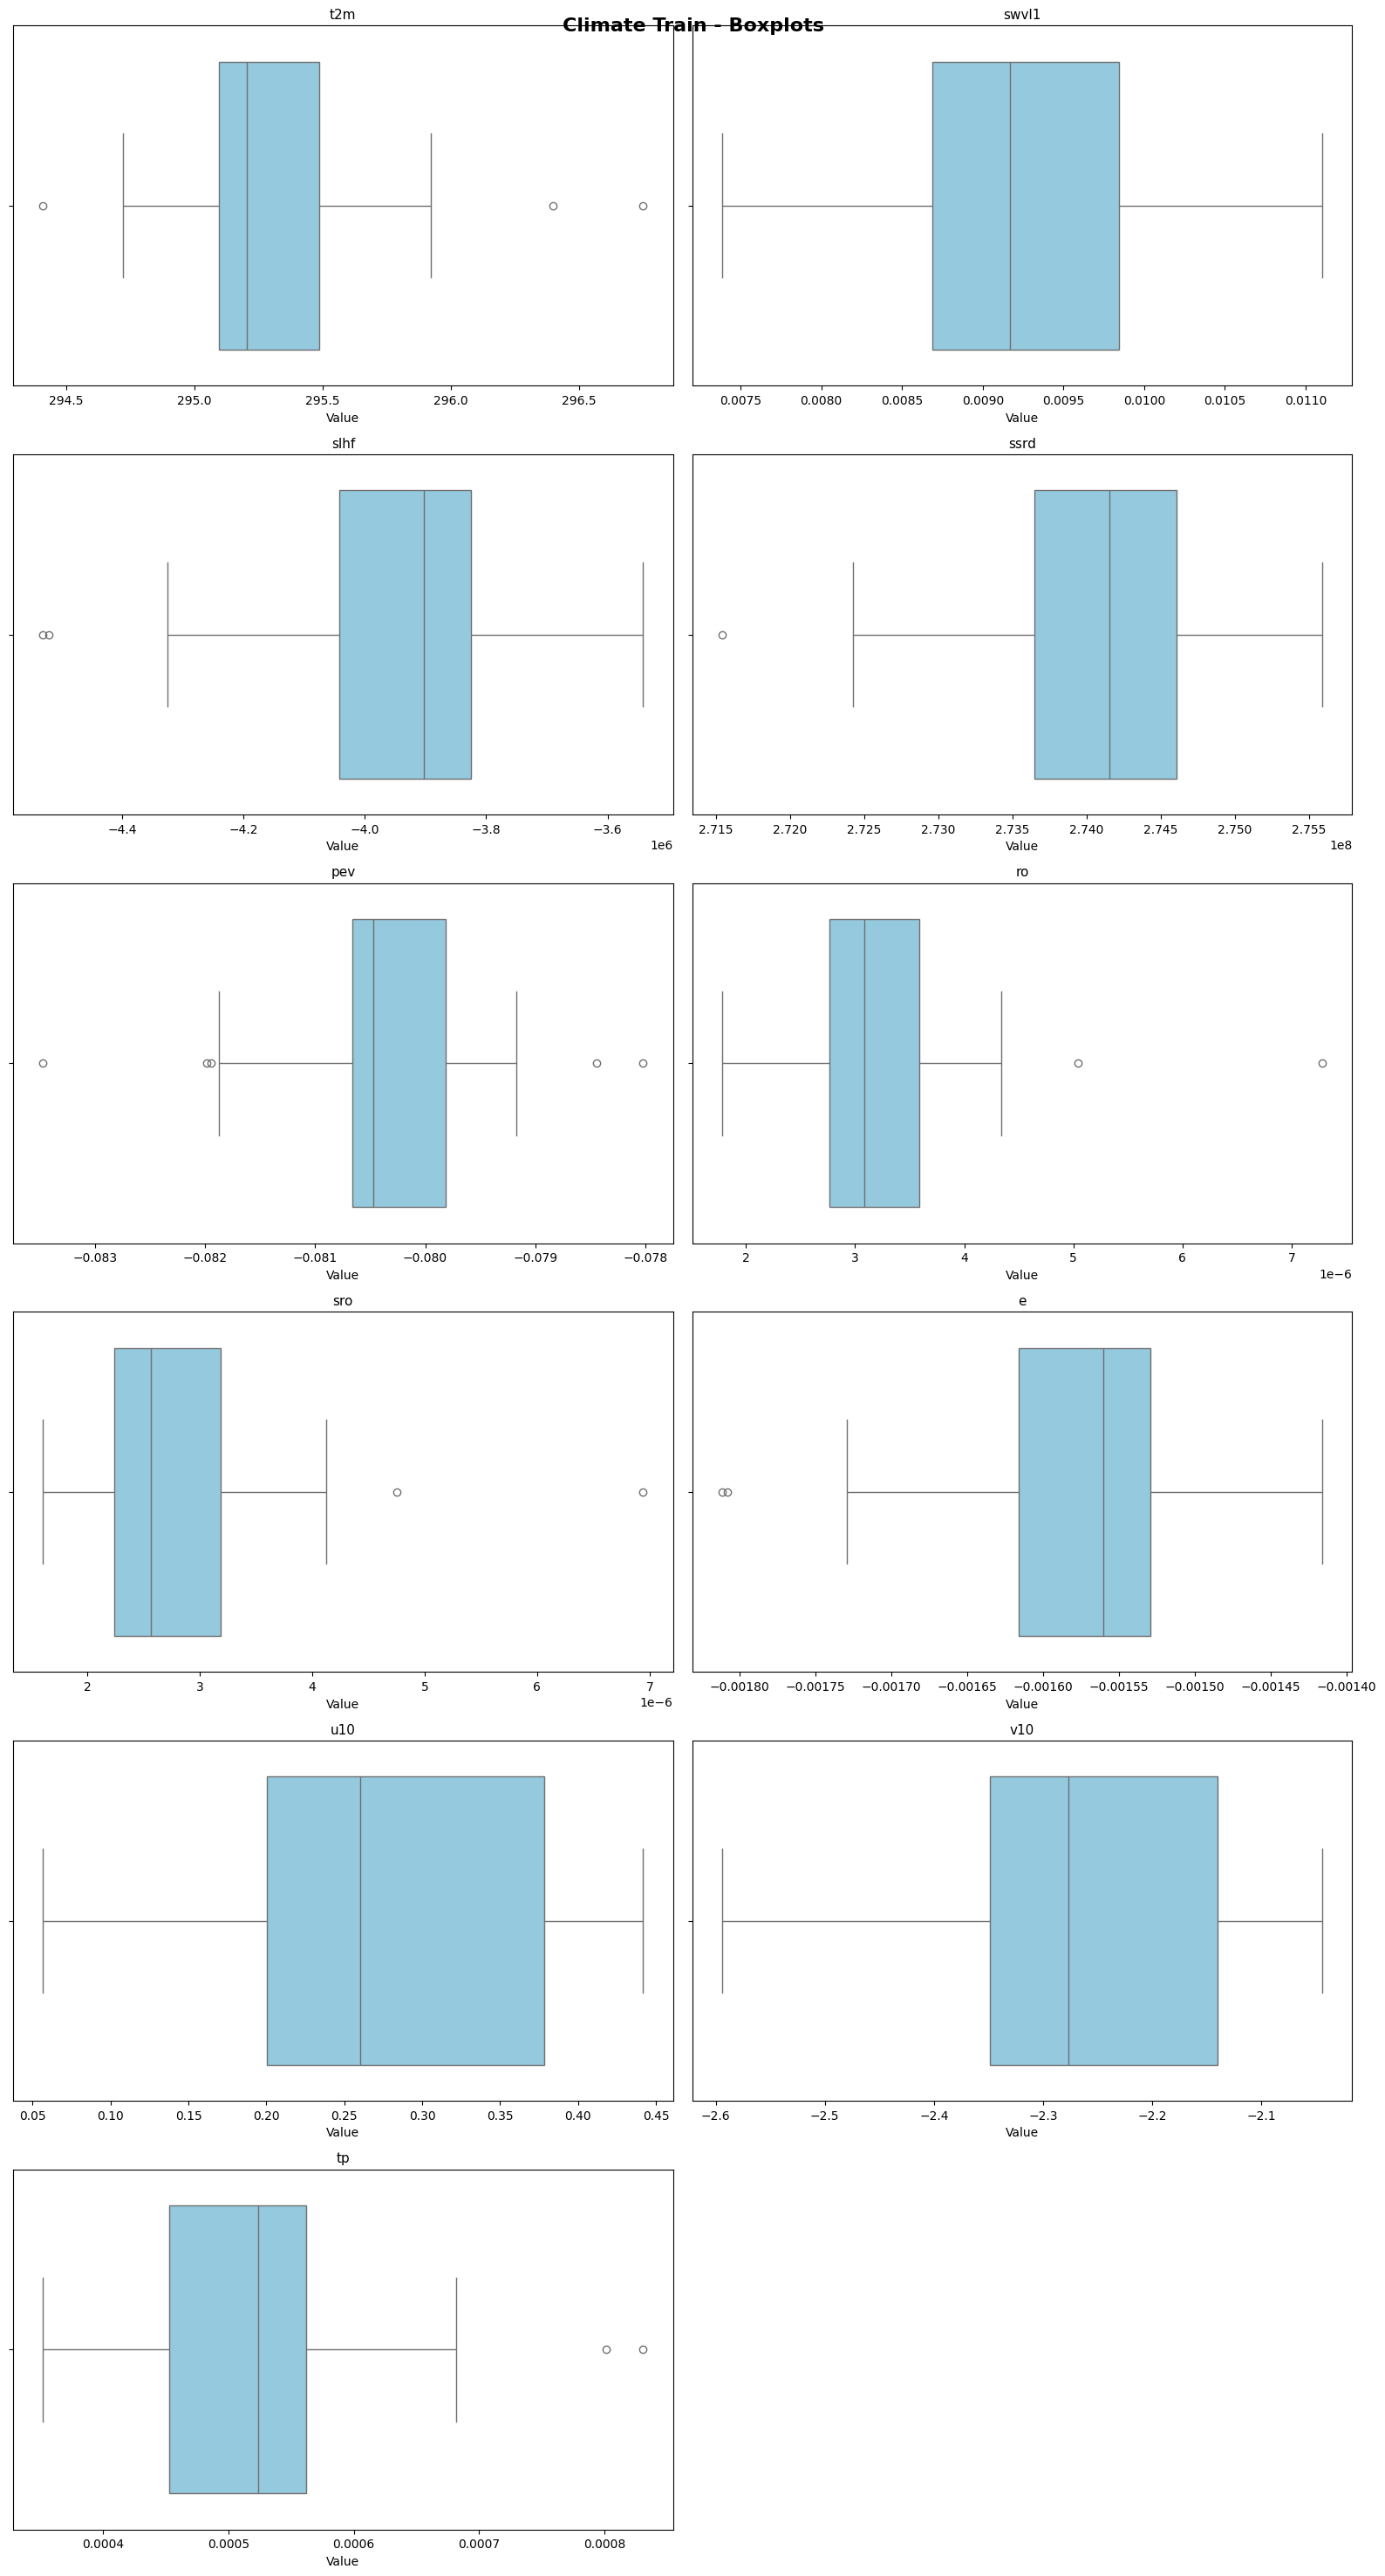

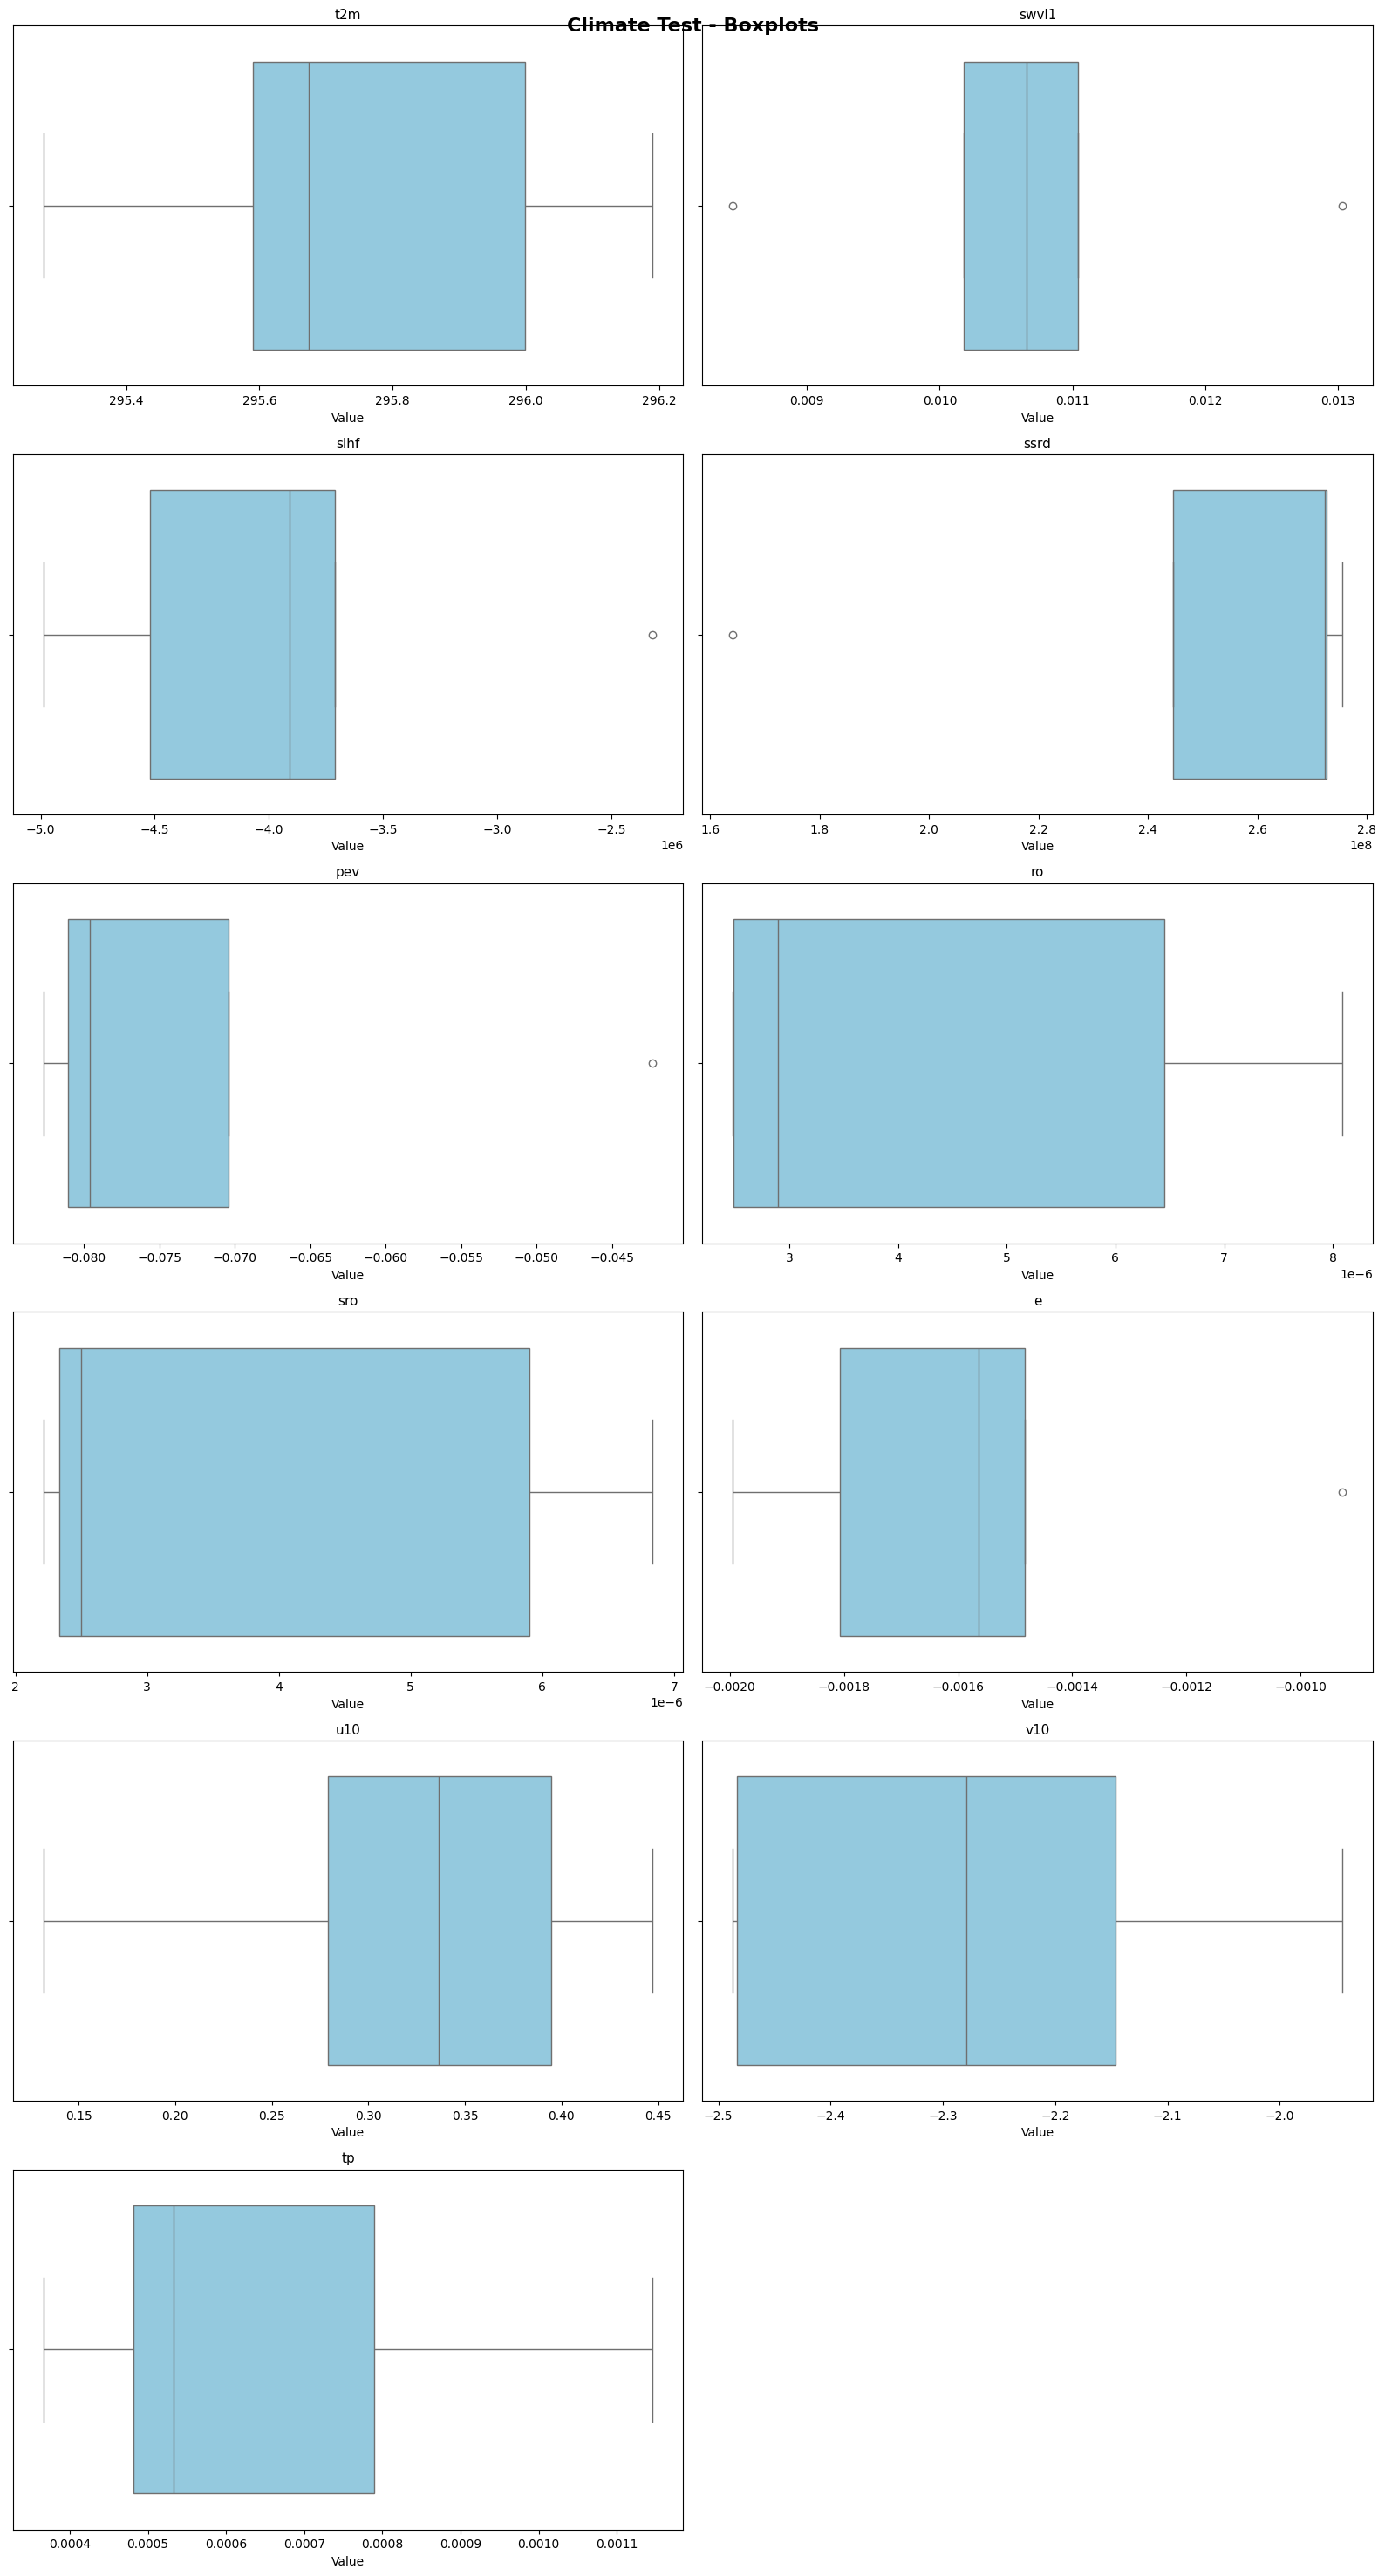

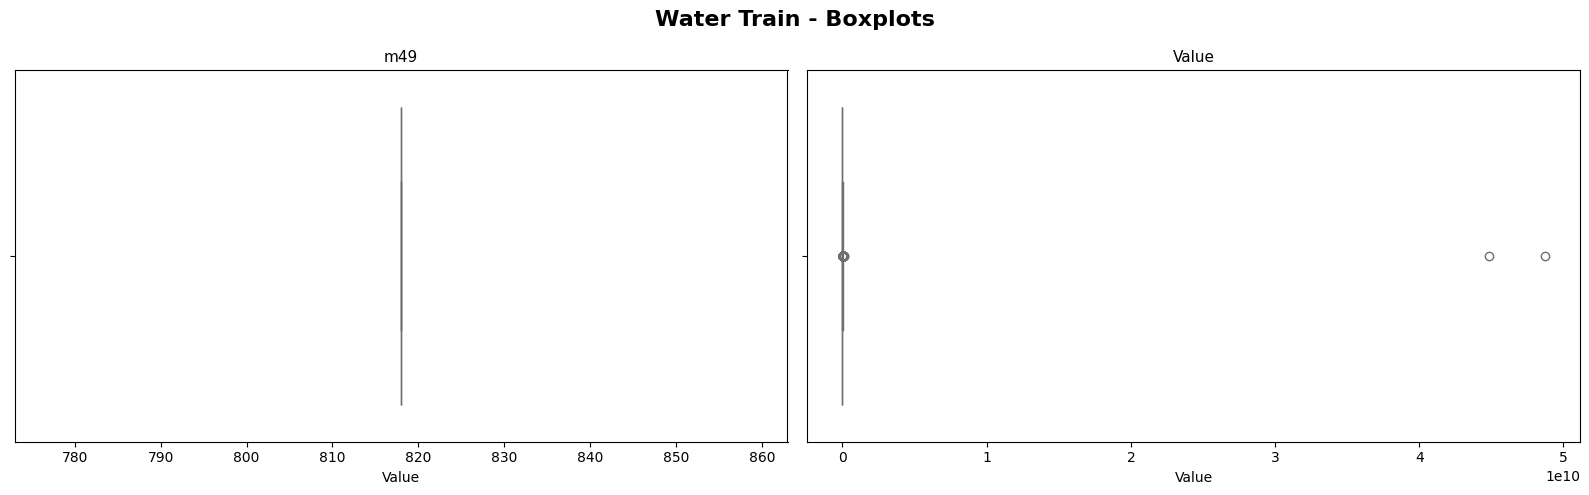

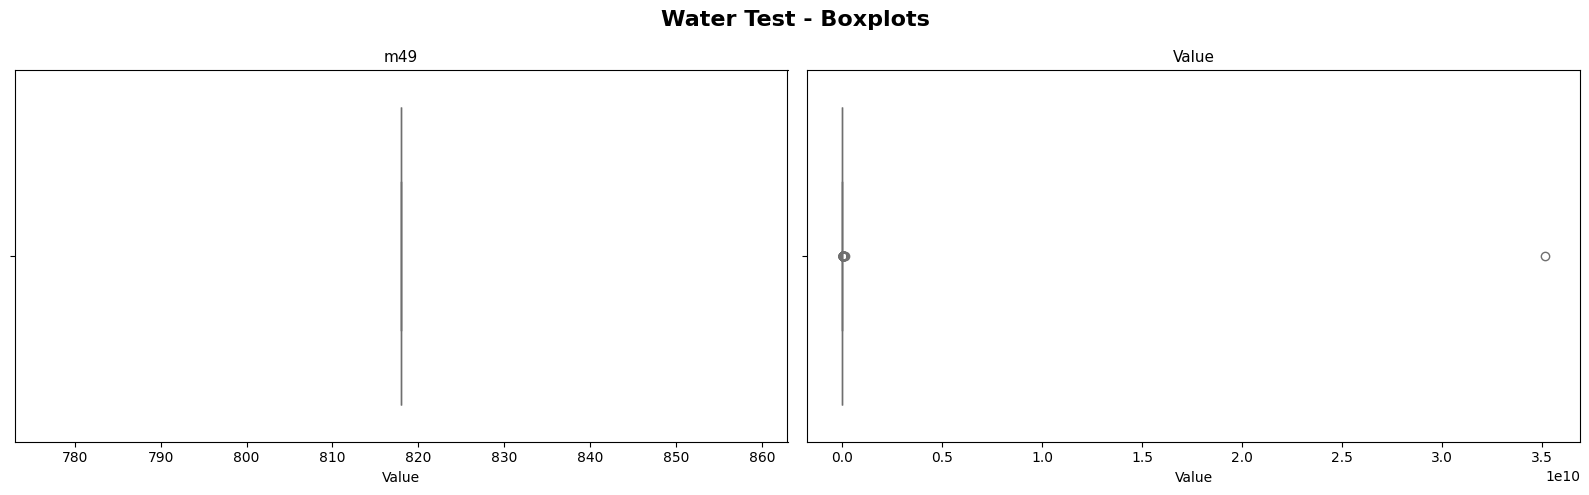

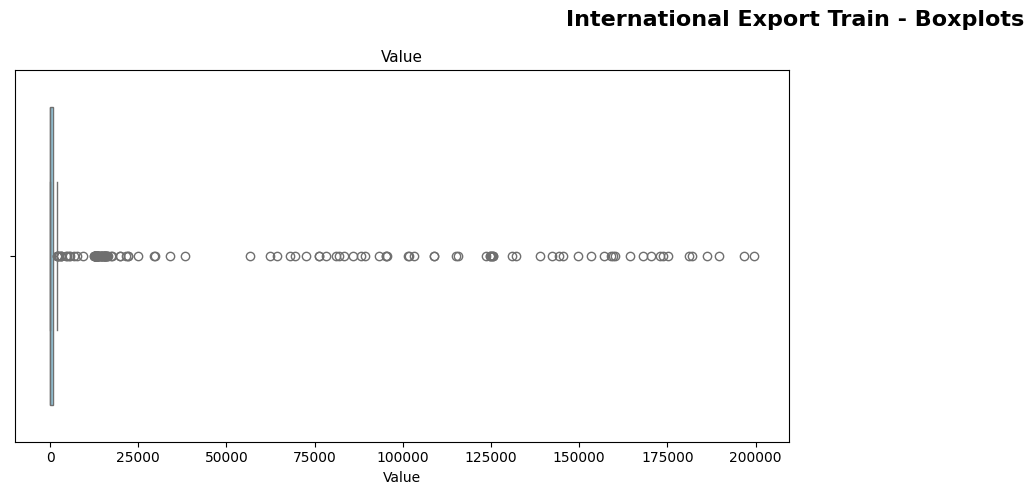

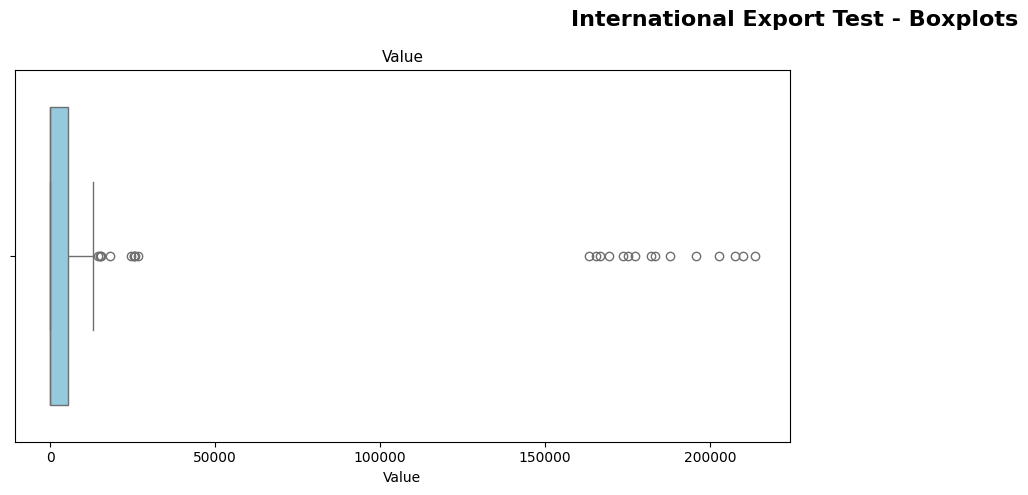

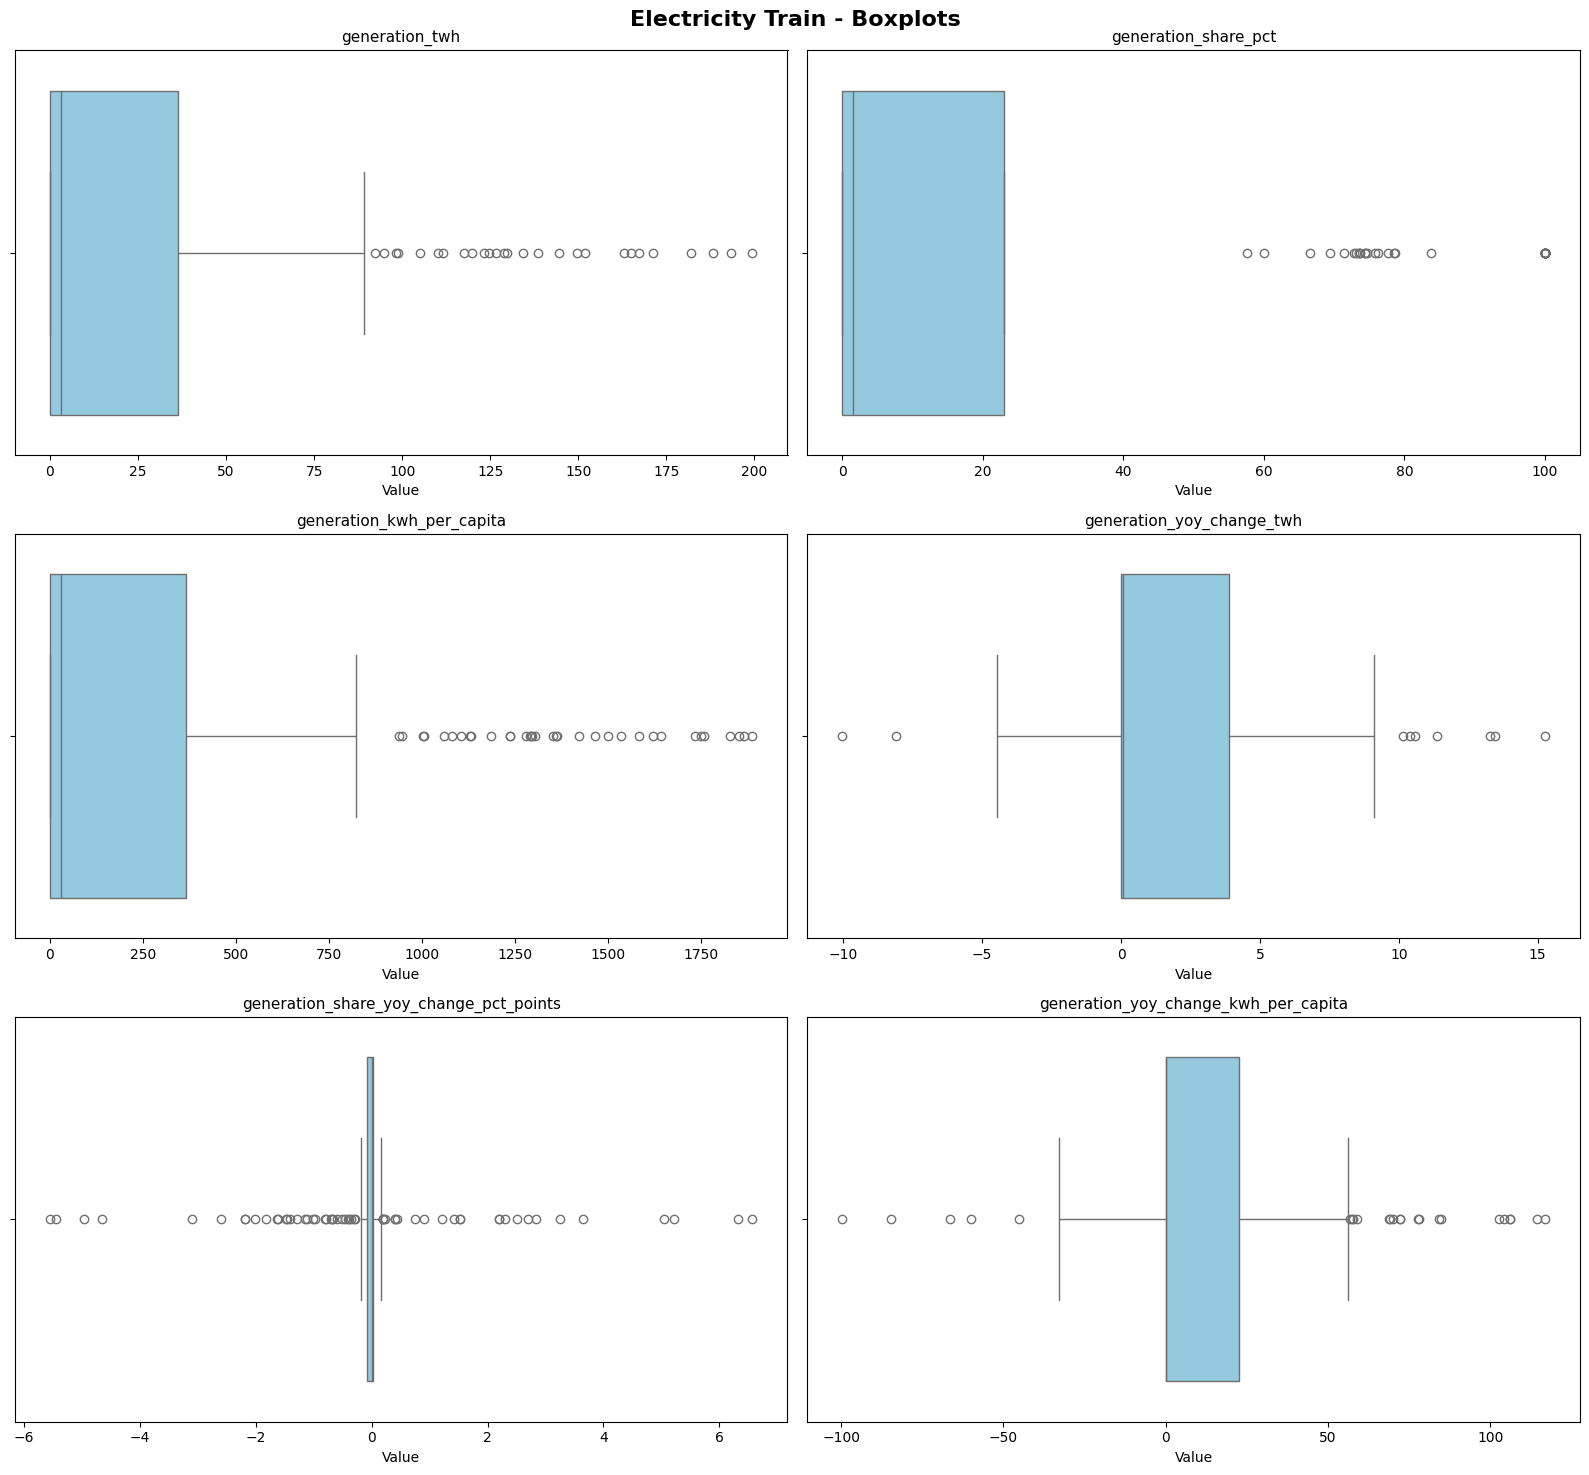

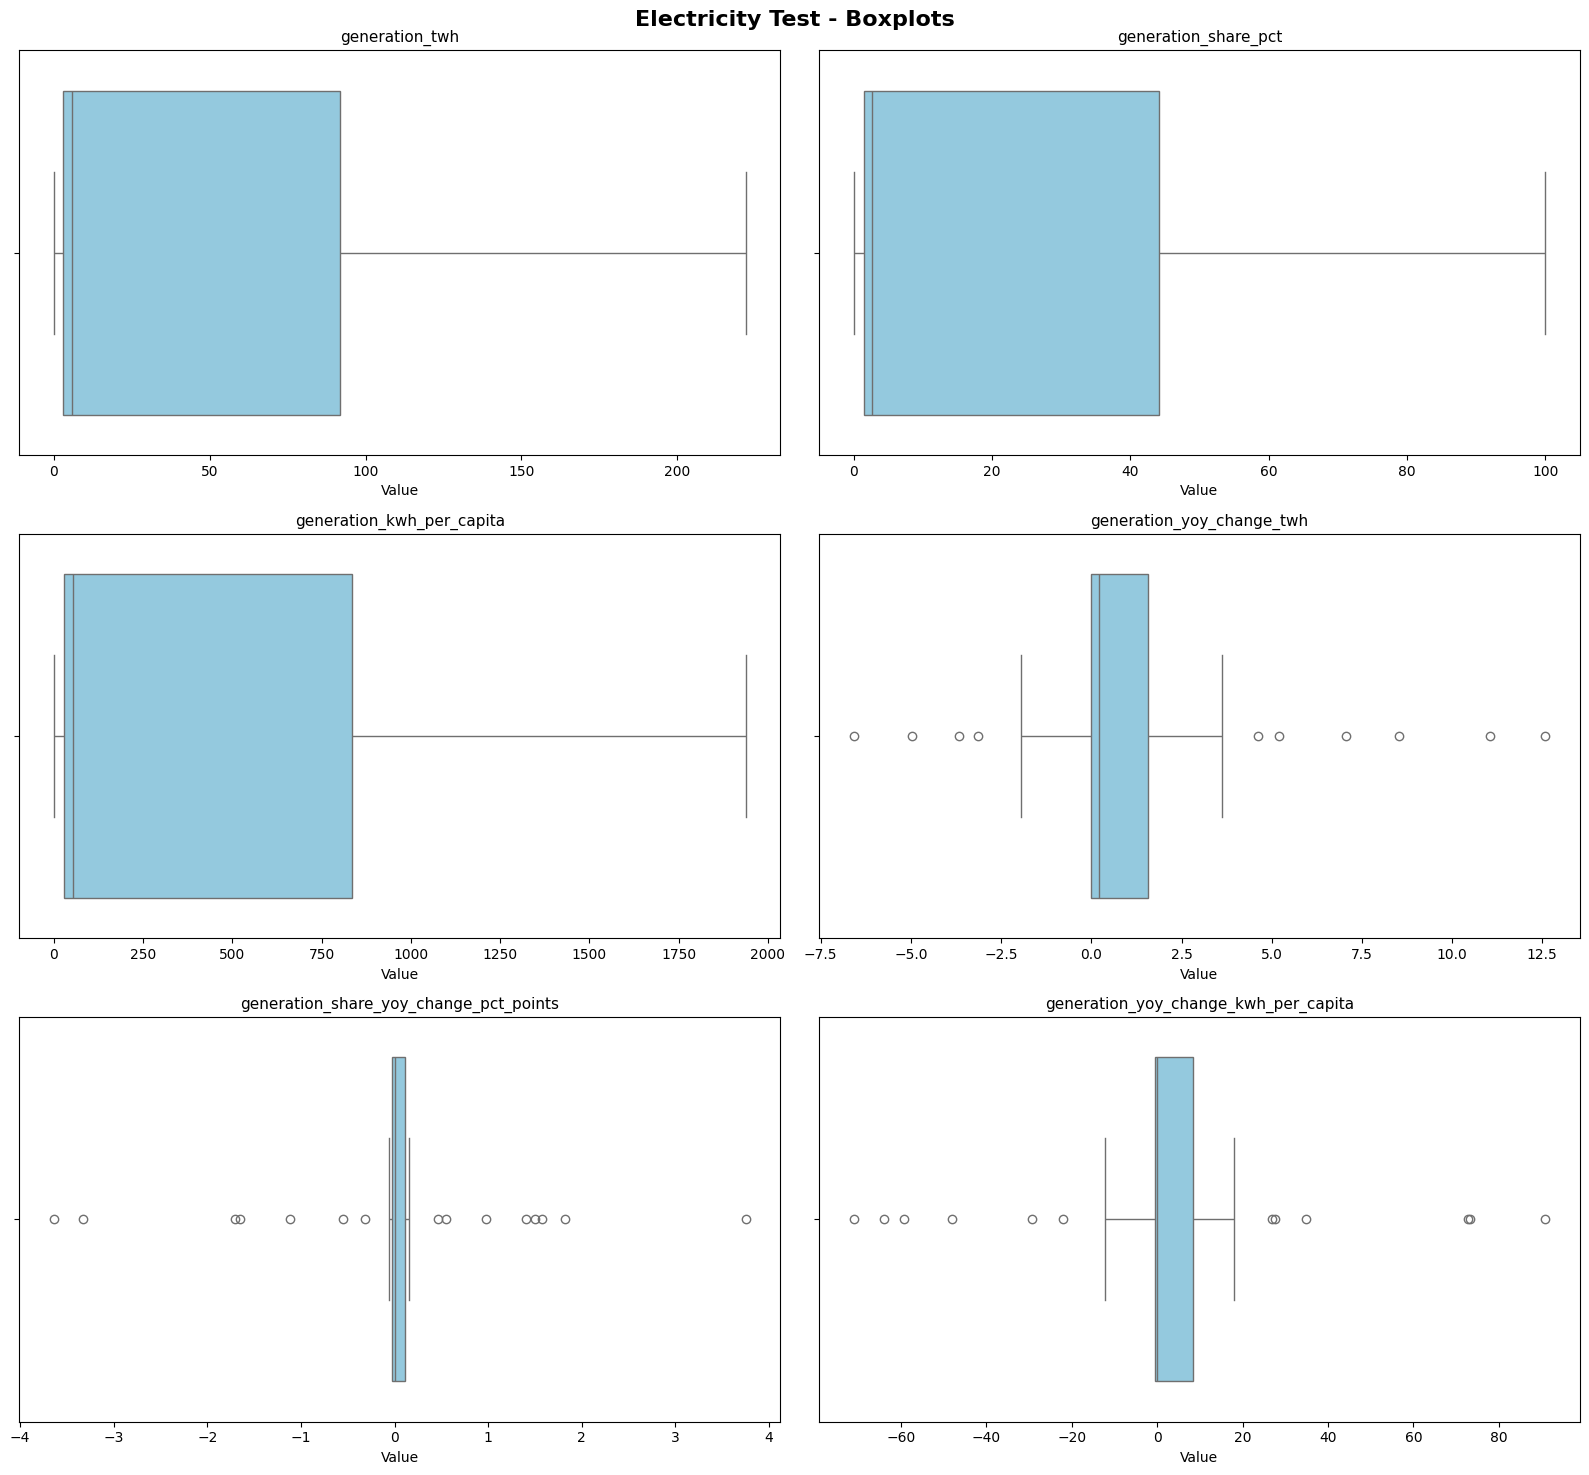

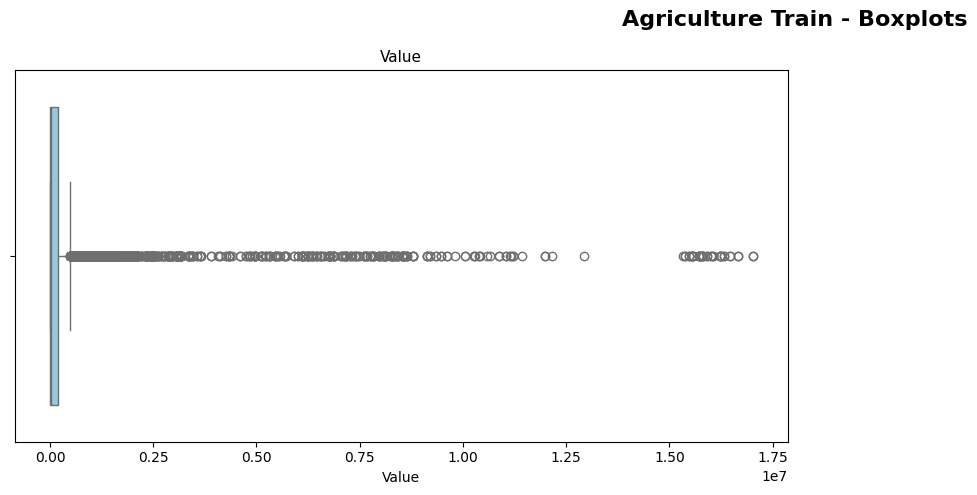

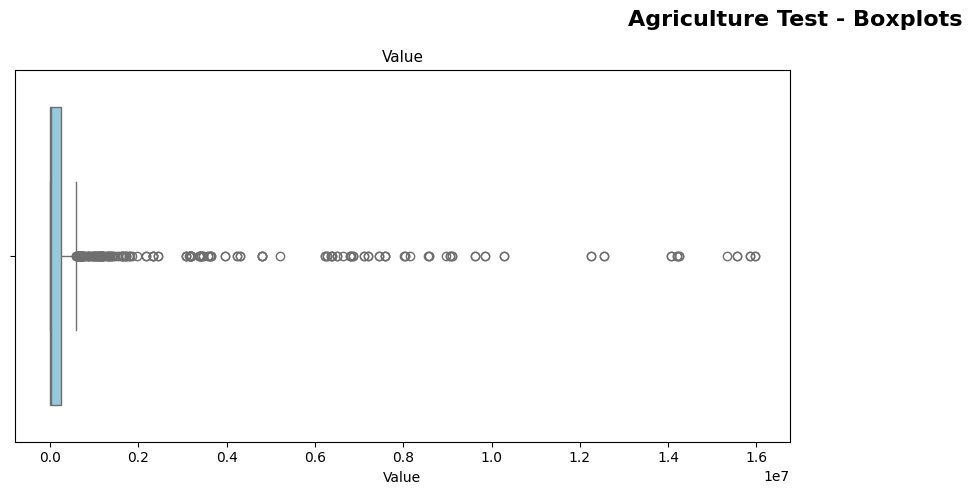

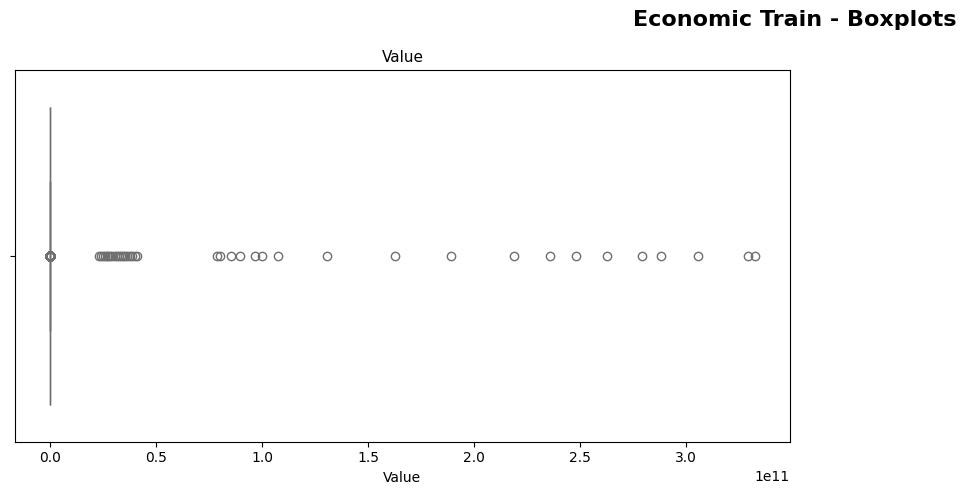

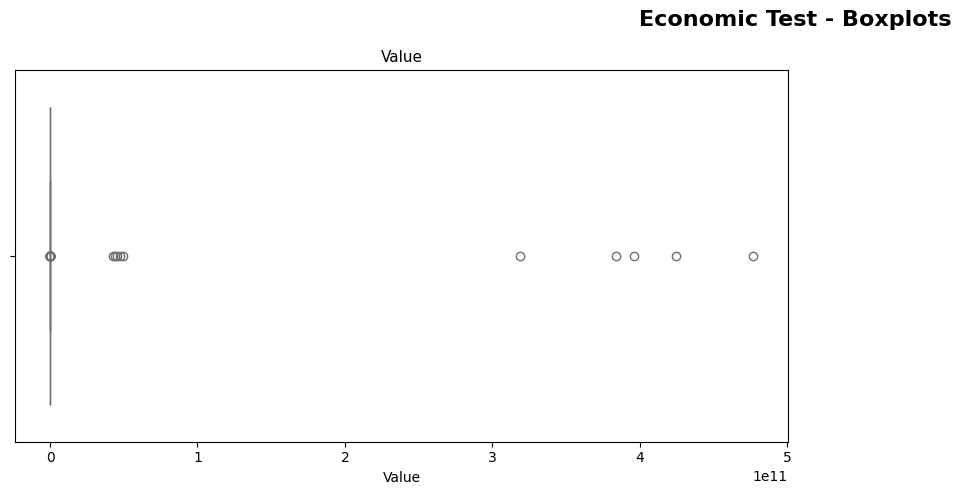

In [325]:

for name, df in zip(df_names, dfs):

    numerical_cols = [
        col for col in df.select_dtypes(include=np.number).columns
        if not any(x in col.lower() for x in ['year', 'code', 'id', 'key'])
    ]

    if not numerical_cols:
        continue

    n_cols = 2
    n_rows = math.ceil(len(numerical_cols) / n_cols)

    fig, axes = plt.subplots(
        n_rows, n_cols,
        figsize=(16, 5 * n_rows)
    )

    axes = np.array(axes).flatten()

    for i, col in enumerate(numerical_cols):

        sns.boxplot(
            x=df[col],
            ax=axes[i],
            color='skyblue'
        )

        axes[i].set_title(col, fontsize=11)
        axes[i].set_xlabel("Value")

    for j in range(len(numerical_cols), len(axes)):
        axes[j].set_visible(False)

    fig.suptitle(
        f"{name} - Boxplots",
        fontsize=16,
        fontweight='bold'
    )

    plt.tight_layout()
    plt.show()


In [326]:
for name, df in datasets.items():
    print(f"{name}: {df.duplicated().sum()} Duplicates")

climate_annual: 0 Duplicates
Water_filtered: 147 Duplicates
int_export: 0 Duplicates
elec_sources_filtered: 0 Duplicates
Agriculture_clean: 720 Duplicates
economic_filtered: 0 Duplicates


In [327]:
for name, df in datasets.items():
    datasets[name] = df.drop_duplicates().copy()
    print(f"{name}: {df.duplicated().sum()} Duplicates Remaining")

climate_annual: 0 Duplicates Remaining
Water_filtered: 147 Duplicates Remaining
int_export: 0 Duplicates Remaining
elec_sources_filtered: 0 Duplicates Remaining
Agriculture_clean: 720 Duplicates Remaining
economic_filtered: 0 Duplicates Remaining


In [328]:
for name, df in datasets.items():
    datasets[name] = df.reset_index(drop=True)
    print(f"{name}: Index Reset Successfully")

climate_annual: Index Reset Successfully
Water_filtered: Index Reset Successfully
int_export: Index Reset Successfully
elec_sources_filtered: Index Reset Successfully
Agriculture_clean: Index Reset Successfully
economic_filtered: Index Reset Successfully


In [329]:
for name, df in datasets.items():
    datasets[name] = df.head( )
    display(datasets[name])

,Year,t2m,swvl1,slhf,ssrd,pev,ro,sro,e,u10,v10,tp
0,2000,294.409063,0.009936,-3892321.44,275248859,-0.078021,0.000003,0.000003,-0.001556,0.400113,-2.594168,0.000552
1,2001,295.091858,0.007815,-3638552.25,275589158,-0.079554,0.000002,0.000002,-0.001455,0.328838,-2.338997,0.000381
2,2002,295.183013,0.009754,-4053215.18,274151582,-0.080010,0.000004,0.000003,-0.001621,0.211584,-2.276578,0.000568
3,2003,295.070053,0.008595,-3814634.56,274354061,-0.080470,0.000004,0.000002,-0.001525,0.371083,-2.143402,0.000450
4,2004,295.122602,0.009150,-3787883.60,274677803,-0.080526,0.000003,0.000002,-0.001515,0.190732,-2.265247,0.000455


,m49,VariableGroup,Subgroup,Variable,Area,Year,Value,Unit,Symbol,IsAggregate
0,818,Irrigation and drainage development,Area equipped for irrigation by source of water,Area equipped for irrigation by direct use of ...,Egypt,2000,88392.76875,feddan,I,False
1,818,Irrigation and drainage development,Area equipped for irrigation by source of water,Area equipped for irrigation by direct use of ...,Egypt,2001,99999.90000,feddan,A,False
2,818,Irrigation and drainage development,Area equipped for irrigation by source of water,Area equipped for irrigation by direct use of ...,Egypt,2002,99999.90000,feddan,I,False
3,818,Irrigation and drainage development,Area equipped for irrigation by source of water,Area equipped for irrigation by direct use of ...,Egypt,2003,99999.90000,feddan,I,False
4,818,Irrigation and drainage development,Area equipped for irrigation by source of water,Area equipped for irrigation by direct use of ...,Egypt,2004,99999.90000,feddan,I,False


,API,Indicator,Year,Value,Level_Indicator
0,INTL.2-7-EGY-MK.A,Capacity (million kW),2000,17.3021,1
1,INTL.27-7-EGY-MK.A,Nuclear (million kW),2000,0.0000,1.1
2,INTL.28-7-EGY-MK.A,Fossil fuels (million kW),2000,14.3560,1.2
3,INTL.29-7-EGY-MK.A,Renewables (million kW),2000,2.9461,1.3
4,INTL.33-7-EGY-MK.A,Hydroelectricity (million kW),2000,2.8100,1.3.1


,entity,entity_code,is_aggregate_entity,Year,series,is_aggregate_series,generation_twh,generation_share_pct,generation_kwh_per_capita,generation_yoy_change_twh,generation_yoy_change_pct,generation_share_yoy_change_pct_points,generation_yoy_change_kwh_per_capita
0,Egypt,EGY,False,2000,Bioenergy,False,0.00,0.00,0.00,0.00,NaN,0.00,0.00
1,Egypt,EGY,False,2000,Coal,False,0.00,0.00,0.00,0.00,NaN,0.00,0.00
2,Egypt,EGY,False,2000,Gas,False,42.19,57.54,577.26,4.96,13.33,0.91,56.77
3,Egypt,EGY,False,2000,Hydro,False,14.18,19.34,194.00,0.74,5.49,-1.11,6.07
4,Egypt,EGY,False,2000,Other fossil,False,16.87,23.01,230.86,1.82,12.10,0.11,20.41


,Domain Code,Domain,Area Code (M49),Area,Element Code,Element,Item Code (CPC),Item,Year Code,Year,Unit,Value,Flag,Flag Description,Note
0,QCL,Crops and livestock products,818,Egypt,5312,Area harvested,1654.0,"Anise, badian, coriander, cumin, caraway, fenn...",2000,2000,feddan,61906.000,E,Estimated value,NaN
1,QCL,Crops and livestock products,818,Egypt,5412,Yield,1654.0,"Anise, badian, coriander, cumin, caraway, fenn...",2000,2000,kg/feddan,355.404,E,Estimated value,NaN
2,QCL,Crops and livestock products,818,Egypt,5510,Production,1654.0,"Anise, badian, coriander, cumin, caraway, fenn...",2000,2000,Ton,22000.000,E,Estimated value,NaN
3,QCL,Crops and livestock products,818,Egypt,5312,Area harvested,1654.0,"Anise, badian, coriander, cumin, caraway, fenn...",2001,2001,feddan,61906.000,E,Estimated value,NaN
4,QCL,Crops and livestock products,818,Egypt,5412,Yield,1654.0,"Anise, badian, coriander, cumin, caraway, fenn...",2001,2001,kg/feddan,355.404,E,Estimated value,NaN


,Country Name,Country Code,Indicator Name,Indicator Code,Year,Value,Category
0,"Egypt, Arab Rep.",EGY,Access to electricity (% of population),EG.ELC.ACCS.ZS,2000,97.700000,Energy
1,"Egypt, Arab Rep.",EGY,Agricultural land (% of land area),AG.LND.AGRI.ZS,2000,3.306042,Agriculture
2,"Egypt, Arab Rep.",EGY,Agricultural raw materials exports (% of merch...,TX.VAL.AGRI.ZS.UN,2000,5.007055,Trade
3,"Egypt, Arab Rep.",EGY,Agricultural raw materials imports (% of merch...,TM.VAL.AGRI.ZS.UN,2000,4.835680,Trade
4,"Egypt, Arab Rep.",EGY,"Agriculture, forestry, and fishing, value adde...",NV.AGR.TOTL.ZS,2000,15.538077,Agriculture
